In [8]:
import re
import unicodedata
from pathlib import Path
from collections import defaultdict, Counter
from nltk.tokenize import word_tokenize
import pandas as pd
import numpy as np
import rasterio
import zipfile
import io
import json
import matplotlib.pyplot as plt
import sys
import glob

IN_FILE  = Path("datasets/resultset.xlsx")
OUT_FILE = Path("datasets/fineli_head_medians.xlsx")
HEAD_FINELLI_NO_LEMMATIZATION = Path("datasets/fineli_head_medians_no_lemmatization.xlsx")
NUMBERS_FILE = Path("datasets/fineli_pre_processed.xlsx")

# Note: zip files are not in git, download them independently and add them to the directory manually
# Source for this zip: https://drive.google.com/file/d/1Dmnco2Bmm--AGRcdxlFaOXOF3K1d2PzK/view?usp=sharing
SUOMI24_CORPUS_01_06_ZIP_PATH = Path("corpus_files/Parsed_data_1_6.zip")
BATCH_SIZE = 500

LESS_THAN_REPLACEMENT_VALUE = 0.05  # "<0.1" is treated as 0.05

In [9]:
def to_number(value):
    """'12.5' -> 12.5, '<0.1' -> 0.05, 'N/A' or empty -> NaN"""
    if pd.isna(value):
        return np.nan
    value = str(value).strip().replace(',', '.')  # In case '12,5' -> '12.5'
    if value.upper() in {'N/A', 'NA', '-', ''}:
        return np.nan
    if value.startswith('<'):  # '<0.1' -> '0.05'
        return LESS_THAN_REPLACEMENT_VALUE
    try:
        return float(value)
    except ValueError:
        return np.nan


def head_term(name):
    """'Ahven, paistettu voissa' -> 'ahven'"""
    head = str(name).split(',')[0]  # text before the first comma
    head = head.split('/')[0]  # first alternative only, 'Aromisuola/yrttisuola 71 %' -> 'aromisuola'
    head = re.split(r'\d', head)[0]  # cut at the first number, 'kasvirasvalevite 70 %' -> 'kasvirasvalevite'
    head = unicodedata.normalize('NFC', head)  # consistent å/ä/ö for later matching
    head = re.sub(r'\s+', ' ', head).strip().lower()  # replace multiple whitespaces with single whitespaceS
    return head

In [10]:
from simplemma import Lemmatizer
from simplemma.strategies import DictionaryLookupStrategy
from simplemma.strategies.dictionaries import DefaultDictionaryFactory

lemmatizer = Lemmatizer(
    lemmatization_strategy=DictionaryLookupStrategy(dictionary_factory=DefaultDictionaryFactory())
)


KEEP_AS_IS = {'tee', 'voi'}   # already the right lemma, but the lemmatizer reads them as verbs

def lemmatize_word(word):
    """'ahvenet' -> 'ahven', 'tee' -> 'tee' (not changed: no inflection ending)"""
    if not word or word in KEEP_AS_IS:
        return word
    return lemmatizer.lemmatize(word, lang='fi').lower()


def lemmatize_term(term):
    """'ahvenet foliossa' -> 'ahven folio', 'ateria-ainekset' -> 'ateria-aines'"""
    return ' '.join('-'.join(lemmatize_word(part) for part in word.split('-'))
                    for word in term.split(' '))

# print(lemmatize_term('ahvenet foliossa'))  # expect: ahven folio
# print(lemmatize_term('herneet'))  # expect: herne
# print(lemmatize_term('ateria-ainekset'))  # check how the hyphen is handled (expect: ateria-aines)
# print(lemmatize_term('tee'))  # expect: tee
# print(lemmatize_term('voi'))  # expect: voi

In [11]:
def read_fineli_raw(in_file):
    return pd.read_excel(in_file, dtype=str)

def convert_to_numbers(raw):
    nutrient_cols = [c for c in raw.columns if c not in ('id', 'name')]
    numbers = raw.copy()
    numbers[nutrient_cols] = raw[nutrient_cols].apply(lambda col: col.map(to_number))
    return numbers

def calculate_medians(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    df = df[df['name'] != '']

    lemma_map = {head: lemmatize_term(head) for head in df['name'].unique()}
    df['name'] = df['name'].map(lemma_map)

    return df.groupby('name').median()

def calculate_medians_no_lemmatization(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    return df.groupby('name').median()

def load_fineli_dataset(in_file=IN_FILE, numbers_file=NUMBERS_FILE, out_file=OUT_FILE):
    raw = read_fineli_raw(in_file)

    numbers = convert_to_numbers(raw)
    # numbers.to_excel(numbers_file, index=False)

    medians = calculate_medians(numbers)
    medians.to_excel(out_file)
    return medians

def load_fineli_medians(out_file=OUT_FILE):
    return pd.read_excel(out_file, index_col=0)

In [12]:
# fineli = load_fineli_dataset()  # creates new finelli_head_medians.xlsx
fineli = load_fineli_medians()
# print("\n", fineli)


fineli_lemmas = set(fineli.index)
fineli_dict = fineli.fillna(0)[~fineli.index.duplicated(keep='first')].to_dict('index')

In [13]:
import gzip, io, json, os, zipfile
from collections import Counter
from pathlib import Path

fineli_lemmas = set(fineli.index)
fineli_dict = (fineli.fillna(0)[~fineli.index.duplicated(keep='first')]
                     .to_dict('index'))

# For multi-word foods such as "ahven folio" (longest match wins)
MAX_NGRAM = max(len(f.split(' ')) for f in fineli_lemmas)
FIRST_WORDS = {f.split(' ')[0] for f in fineli_lemmas}

OUT_DIR = Path("datasets/parsed")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def find_foods(lemmas):
    """lemmas: list of lowercase str -> Counter({food: n_occurrences})"""
    found, i, n = Counter(), 0, len(lemmas)
    while i < n:
        if lemmas[i] in FIRST_WORDS:
            for k in range(min(MAX_NGRAM, n - i), 0, -1):
                cand = ' '.join(lemmas[i:i + k])
                if cand in fineli_lemmas:
                    found[cand] += 1
                    i += k
                    break
            else:
                i += 1
        else:
            i += 1
    return found


def lower_list(xs):
    return [str(w).lower() for w in (xs or [])]


def make_message(idx, date, raw_tokens, lemmas, foods):
    return {
        "idx": idx,  # 0 = thread start, 1...n = comments
        "date": date,
        "text": ' '.join(map(str, raw_tokens or [])),
        "lemmas": ' '.join(lemmas),
        "foods": dict(foods),
    }


def process_thread(d, out_f, stats):
    date = str(d.get("date") or "")
    month = date[:7]
    if len(month) != 7:
        return

    title = d.get("title") or ""
    title_lem = lower_list(d.get("orig_msg_lemmatized"))
    comments = d.get("comments") or []

    # Monthly totals over all threads
    # (could probably be removed but decided to add to see better if the script works)
    s = stats.setdefault(month, Counter())
    s["threads"] += 1
    s["comments"] += len(comments)
    s["tokens"] += len(title_lem)

    title_foods = find_foods(title_lem)
    thread_foods = Counter(title_foods)
    messages = []
    if title_foods:
        messages.append(make_message(0, date, d.get("orig_msg"), title_lem, title_foods))

    for i, c in enumerate(comments, start=1):
        c_lem = lower_list(c.get("orig_msg_lemmatized"))
        s["tokens"] += len(c_lem)
        f = find_foods(c_lem)
        if f:
            thread_foods.update(f)
            messages.append(make_message(i, c.get("date") or date,
                                         c.get("orig_msg"), c_lem, f))

    if not thread_foods:
        return
    s["matched_threads"] += 1

    out_f.write(json.dumps({
        "thread_id": d.get("thread_id"),
        "topic": d.get("topic_names"),
        "date": date,
        "month": month,
        "title": title,
        "title_lemmas": ' '.join(title_lem),
        "title_n_tokens": len(title_lem),
        "title_n_chars": len(title),
        "n_comments": len(comments),
        "foods": dict(thread_foods),  # total mentions, title + comments
        "foods_in_title": sorted(title_foods),
        "messages": messages,
    }, ensure_ascii=False) + "\n")


def parse_zip(zip_path):
    zip_path = Path(zip_path)
    with zipfile.ZipFile(zip_path) as z:
        files = [f for f in z.namelist() if f.endswith("with_comments.txt")]
        for file_name in files:
            tag = file_name.split('/')[-2]
            out_path = OUT_DIR / f"{zip_path.stem}_{tag}.jsonl.gz"
            stats_path = OUT_DIR / f"{zip_path.stem}_{tag}_stats.json"
            if out_path.exists() and stats_path.exists():
                print(f"Skipping {file_name} (already parsed)")
                continue

            print(f"Processing {file_name}")
            tmp = Path(str(out_path) + ".tmp")
            stats = {}
            with z.open(file_name) as raw, io.TextIOWrapper(raw, encoding="utf-8") as text, \
                 gzip.open(tmp, "wt", encoding="utf-8") as out_f:
                for n, line in enumerate(text):
                    line = line.strip()
                    if not line:
                        continue
                    try:
                        d = json.loads(line)
                    except json.JSONDecodeError:
                        continue
                    if n == 0:
                        print("  keys:", list(d.keys()))
                        print("  title:", d.get("title"), "| orig_msg:", d.get("orig_msg"))
                    process_thread(d, out_f, stats)

            os.replace(tmp, out_path)   # file only appears once it is complete
            with open(stats_path, "w", encoding="utf-8") as f:
                json.dump({m: dict(c) for m, c in stats.items()}, f)


In [7]:
# parse_zip(SUOMI24_CORPUS_01_06_ZIP_PATH)

In [14]:
def load_monthly_counts():
    """month x food table of mention counts, read from the parsed files."""
    rows = []
    for p in glob.glob(str(OUT_DIR / "*.jsonl.gz")):
        with gzip.open(p, "rt", encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                for food, n in r["foods"].items():
                    rows.append((r["month"], food, n))
    return (pd.DataFrame(rows, columns=["month", "food", "n"])
              .groupby(["month", "food"])["n"].sum().unstack(fill_value=0))


counts = load_monthly_counts()
# print(counts.head(1))

food_nutrients = pd.DataFrame.from_dict(fineli_dict, orient='index')
# for each month sum of nutrients (times the food was mentioned * nutrition per food)
monthly_nutrition_df = counts.dot(food_nutrients.loc[counts.columns])

# print("Total counts of top 10 foods:")
# print(counts.sum().nlargest(10))

In [9]:
# print(monthly_nutrition_df.head(2))

In [15]:
NUTRIENT_NAMES_EN = {
    'energia, laskennallinen (kJ)': 'energy, calculated (kJ)',
    'rasva (g)': 'fat (g)',
    'hiilihydraatti imeytyvä (g)': 'carbohydrate, digestible (g)',
    'proteiini (g)': 'protein (g)',
    'alkoholi (g)': 'alcohol (g)',
    'orgaaniset hapot (g)': 'organic acids (g)',
    'sokerialkoholi (g)': 'sugar alcohol (g)',
    'sokerit (g)': 'sugars (g)',
    'fruktoosi (g)': 'fructose (g)',
    'galaktoosi (g)': 'galactose (g)',
    'glukoosi (g)': 'glucose (g)',
    'laktoosi (g)': 'lactose (g)',
    'maltoosi (g)': 'maltose (g)',
    'sakkaroosi (g)': 'sucrose (g)',
    'tärkkelys (g)': 'starch (g)',
    'kuitu, kokonais- (g)': 'fibre, total (g)',
    'kuitu veteen liukenematon (g)': 'fibre, water-insoluble (g)',
    'polysakkaridi, vesiliukoinen ei-selluloosa (g)': 'polysaccharide, water-soluble non-cellulose (g)',
    'rasvahapot yhteensä (g)': 'fatty acids, total (g)',
    'rasvahapot monityydyttymättömät (g)': 'fatty acids, polyunsaturated (g)',
    'rasvahapot yksittäistyydyttymättömät cis (g)': 'fatty acids, monounsaturated cis (g)',
    'rasvahapot tyydyttyneet (g)': 'fatty acids, saturated (g)',
    'rasvahapot trans (g)': 'fatty acids, trans (g)',
    'rasvahapot n-3 monityydyttymättömät (g)': 'fatty acids, n-3 polyunsaturated (g)',
    'rasvahapot n-6 monityydyttymättömät (g)': 'fatty acids, n-6 polyunsaturated (g)',
    'rasvahappo 18:2 cis,cis n-6 (linolihappo) (mg)': 'fatty acid 18:2 cis,cis n-6 (linoleic acid) (mg)',
    'rasvahappo 18:3 n-3 (alfalinoleenihappo) (mg)': 'fatty acid 18:3 n-3 (alpha-linolenic acid) (mg)',
    'rasvahappo 20:5 n-3 (EPA) (mg)': 'fatty acid 20:5 n-3 (EPA) (mg)',
    'rasvahappo 22:6 n-3 (DHA) (mg)': 'fatty acid 22:6 n-3 (DHA) (mg)',
    'kolesteroli (GC) (mg)': 'cholesterol (GC) (mg)',
    'sterolit (mg)': 'sterols (mg)',
    'kalsium (mg)': 'calcium (mg)',
    'rauta (mg)': 'iron (mg)',
    'jodidi (jodi) (µg)': 'iodide (iodine) (µg)',
    'kalium (mg)': 'potassium (mg)',
    'magnesium (mg)': 'magnesium (mg)',
    'natrium (mg)': 'sodium (mg)',
    'suola (mg)': 'salt (mg)',
    'fosfori (mg)': 'phosphorus (mg)',
    'seleeni (µg)': 'selenium (µg)',
    'sinkki (mg)': 'zinc (mg)',
    'tryptofaani (mg)': 'tryptophan (mg)',
    'folaatti, kokonais- (µg)': 'folate, total (µg)',
    'niasiiniekvivalentti NE (mg)': 'niacin equivalents NE (mg)',
    'niasiini (nikotiinihappo + nikotiiniamidi) (mg)': 'niacin (nicotinic acid + nicotinamide) (mg)',
    'pyridoksiini vitameerit (vetykloridi) (B6) (mg)': 'pyridoxine vitamers (hydrochloride) (B6) (mg)',
    'riboflaviini (B2) (mg)': 'riboflavin (B2) (mg)',
    'tiamiini (B1) (mg)': 'thiamin (B1) (mg)',
    'A-vitamiini RAE (µg)': 'vitamin A RAE (µg)',
    'karotenoidit (µg)': 'carotenoids (µg)',
    'B12-vitamiini (kobalamiini) (µg)': 'vitamin B12 (cobalamin) (µg)',
    'C-vitamiini (mg)': 'vitamin C (mg)',
    'D-vitamiini (µg)': 'vitamin D (µg)',
    'E-vitamiini alfatokoferoli (mg)': 'vitamin E alpha-tocopherol (mg)',
    'K-vitamiini (µg)': 'vitamin K (µg)',
}

In [11]:
def draw_monthly_nutrition_intake(monthly_df):
    """
    Draw monthly intake evolution of nutrients.
    monthly_df: DataFrame, index = 'YYYY-MM', columns = nutrient names.
    """
    final_results_df = monthly_df.copy()
    final_results_df.index.name = 'Month'
    final_results_df = final_results_df.sort_index()
    final_results_df.index = final_results_df.index.astype(str)

    nutrient_groups = {
        "Energy (kJ)": [
            'energia, laskennallinen (kJ)'
        ],
        "Main Macros (g)": [
            'proteiini (g)', 'hiilihydraatti imeytyvä (g)', 'rasva (g)', 'alkoholi (g)'
        ],
        "Carbs, Sugars & Fibers (g)": [
            'sokerit (g)', 'fruktoosi (g)', 'galaktoosi (g)', 'glukoosi (g)',
            'laktoosi (g)', 'maltoosi (g)', 'sakkaroosi (g)', 'tärkkelys (g)',
            'kuitu, kokonais- (g)', 'kuitu veteen liukenematon (g)',
            'polysakkaridi, vesiliukoinen ei-selluloosa (g)', 'sokerialkoholi (g)'
        ],
        "Fatty Acids (g)": [
            'rasvahapot yhteensä (g)', 'rasvahapot monityydyttymättömät (g)',
            'rasvahapot yksittäistyydyttymättömät cis (g)', 'rasvahapot tyydyttyneet (g)',
            'rasvahapot trans (g)', 'rasvahapot n-3 monityydyttymättömät (g)',
            'rasvahapot n-6 monityydyttymättömät (g)', 'orgaaniset hapot (g)', 'tryptofaani (mg)'
        ],
        "Specific Fats & Cholesterol (mg)": [
            'rasvahappo 18:2 cis,cis n-6 (linolihappo) (mg)',
            'rasvahappo 18:3 n-3 (alfalinoleenihappo) (mg)',
            'rasvahappo 20:5 n-3 (EPA) (mg)', 'rasvahappo 22:6 n-3 (DHA) (mg)',
            'kolesteroli (GC) (mg)', 'sterolit (mg)'
        ],
        "Minerals & Salts (mg)": [
            'kalsium (mg)', 'rauta (mg)', 'kalium (mg)', 'magnesium (mg)',
            'natrium (mg)', 'suola (mg)', 'fosfori (mg)', 'sinkki (mg)'
        ],
        "Minerals & Salts (µg)": [
            'jodidi (jodi) (µg)', 'seleeni (µg)',
        ],
        "Vitamins (mg)": [
            'C-vitamiini (mg)', 'E-vitamiini alfatokoferoli (mg)',
            'niasiiniekvivalentti NE (mg)',
            'niasiini (nikotiinihappo + nikotiiniamidi) (mg)',
            'pyridoksiini vitameerit (vetykloridi) (B6) (mg)',
            'riboflaviini (B2) (mg)', 'tiamiini (B1) (mg)'
        ],
        "Vitamins (µg)": [
            'A-vitamiini RAE (µg)', 'B12-vitamiini (kobalamiini) (µg)',
            'D-vitamiini (µg)', 'K-vitamiini (µg)', 'folaatti, kokonais- (µg)',
            'karotenoidit (µg)'
        ]
    }

    for group_name, columns in nutrient_groups.items():
        valid_cols = [col for col in columns if col in final_results_df.columns]

        if not valid_cols:
            print(f"Skipping {group_name} because none of those columns exist in the dataframe.")
            continue

        plt.figure(figsize=(21, 7))

        for col in valid_cols:
           plt.plot(final_results_df.index, final_results_df[col], marker='o', label=NUTRIENT_NAMES_EN.get(col, col))

        plt.title(f"Monthly Evolution: {group_name}", fontsize=16, fontweight='bold')
        plt.xlabel("Month", fontsize=12)
        plt.ylabel("Total nutrition (100g per mention)", fontsize=12)
        tick_positions = list(range(0, len(final_results_df.index), 6))
        # Ensure the last month is always shown
        last_position = len(final_results_df.index) - 1
        if last_position not in tick_positions:
            tick_positions.append(last_position)
        plt.xticks(
            ticks=tick_positions,
            labels=final_results_df.index[tick_positions],
            rotation=45,
            ha='right'
        )
        plt.plot([], [], ' ', label="Each time a food is mentioned,\nthe total amount is appended\nby the nutrient amount in\n100 grams of the food")
        plt.legend(loc='upper left', bbox_to_anchor=(1, 1), borderaxespad=0.)

        plt.grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()

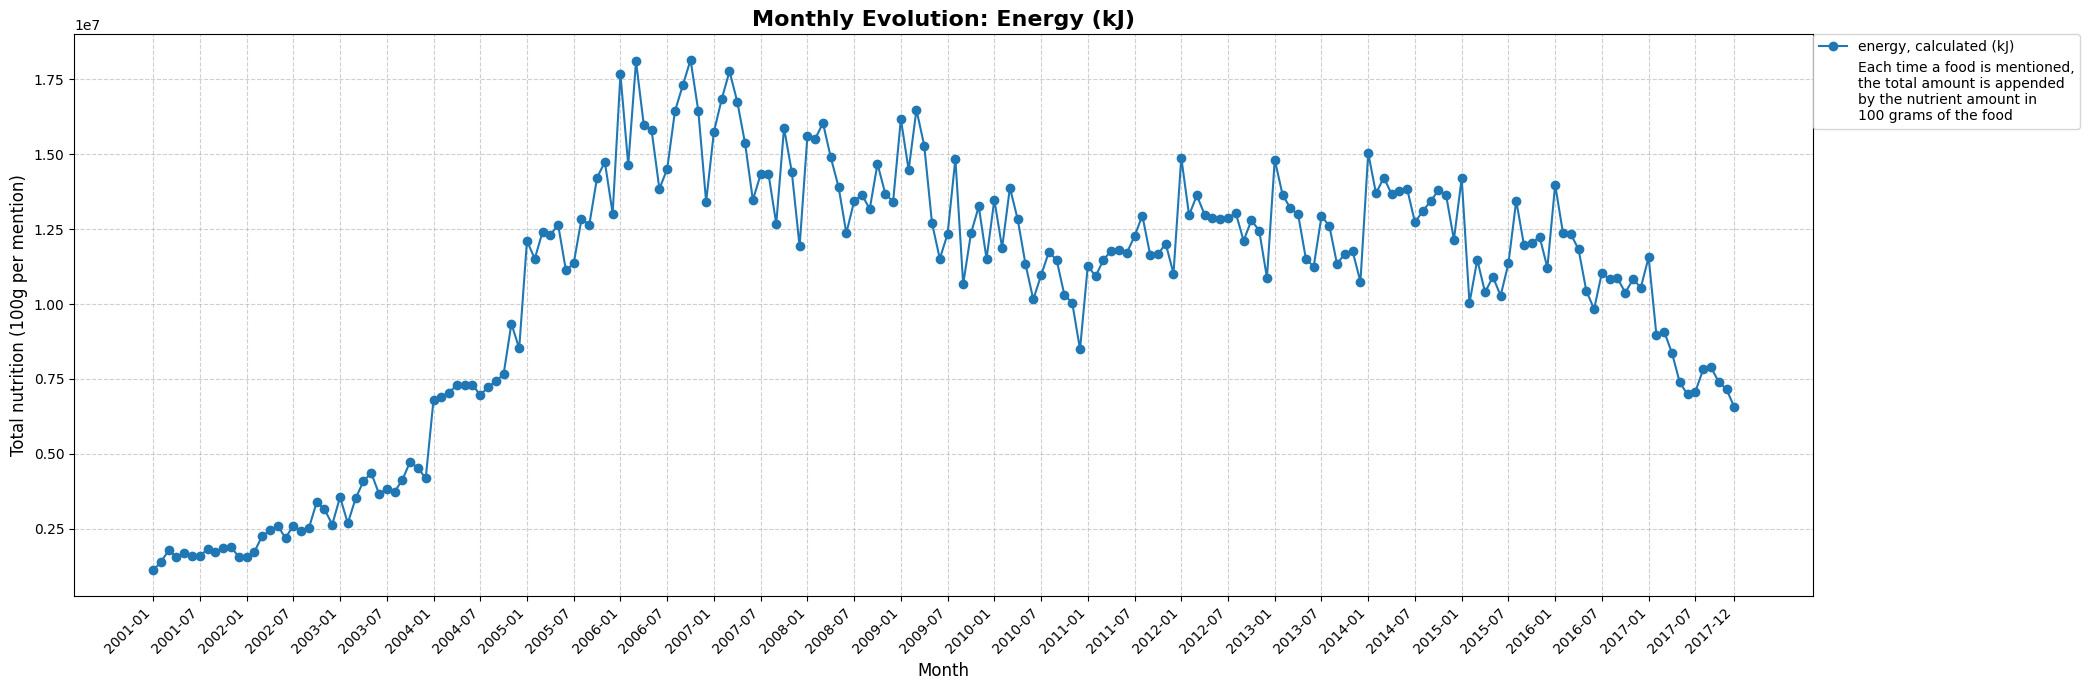

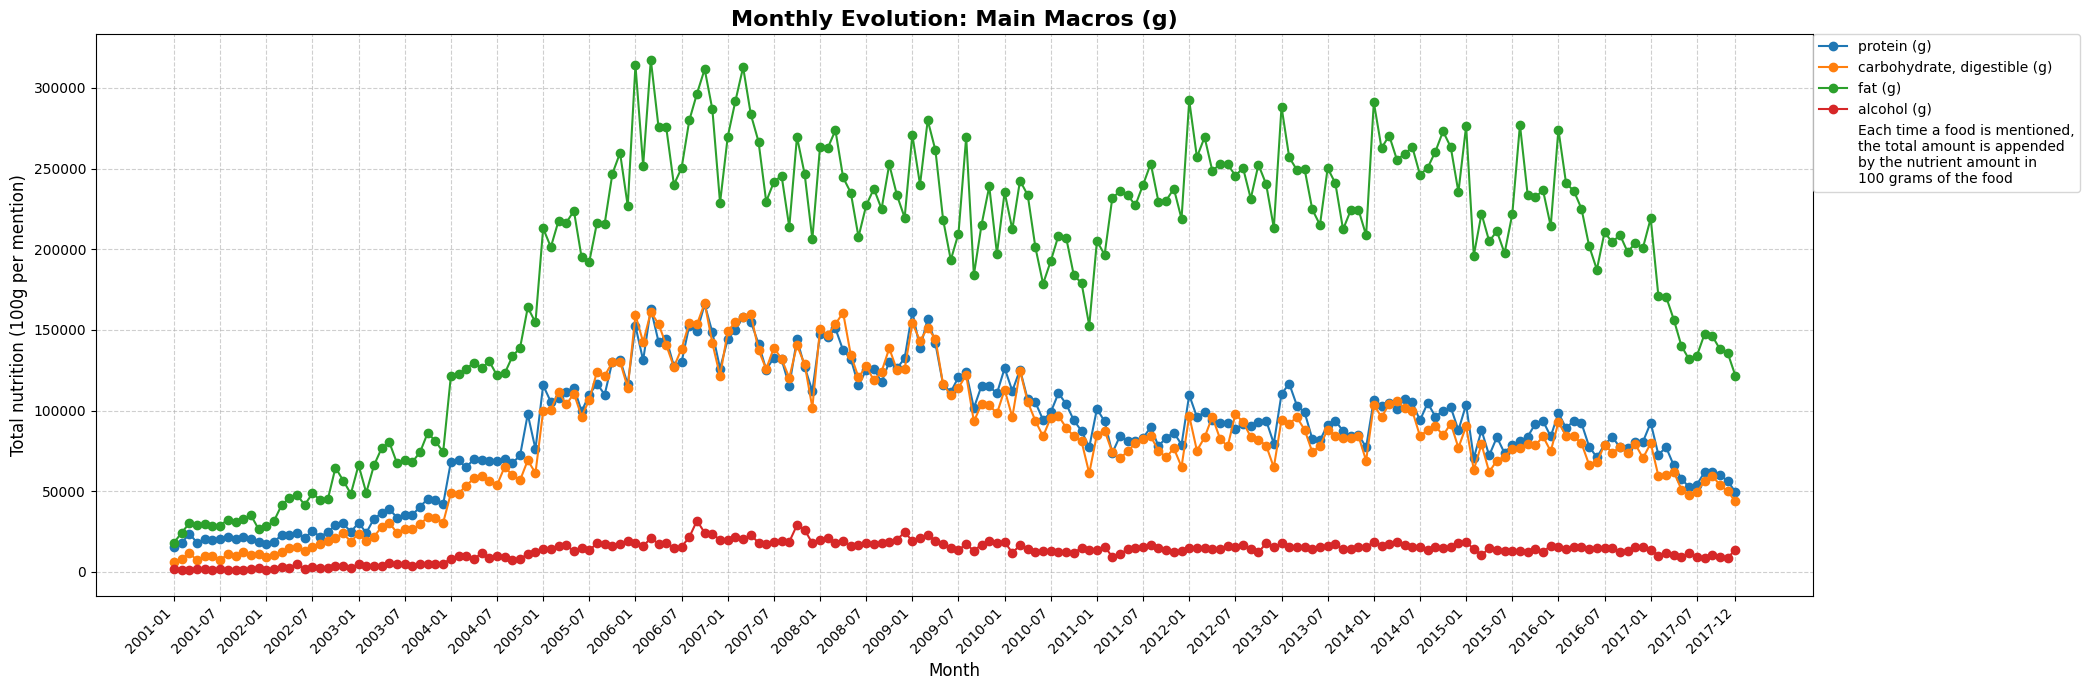

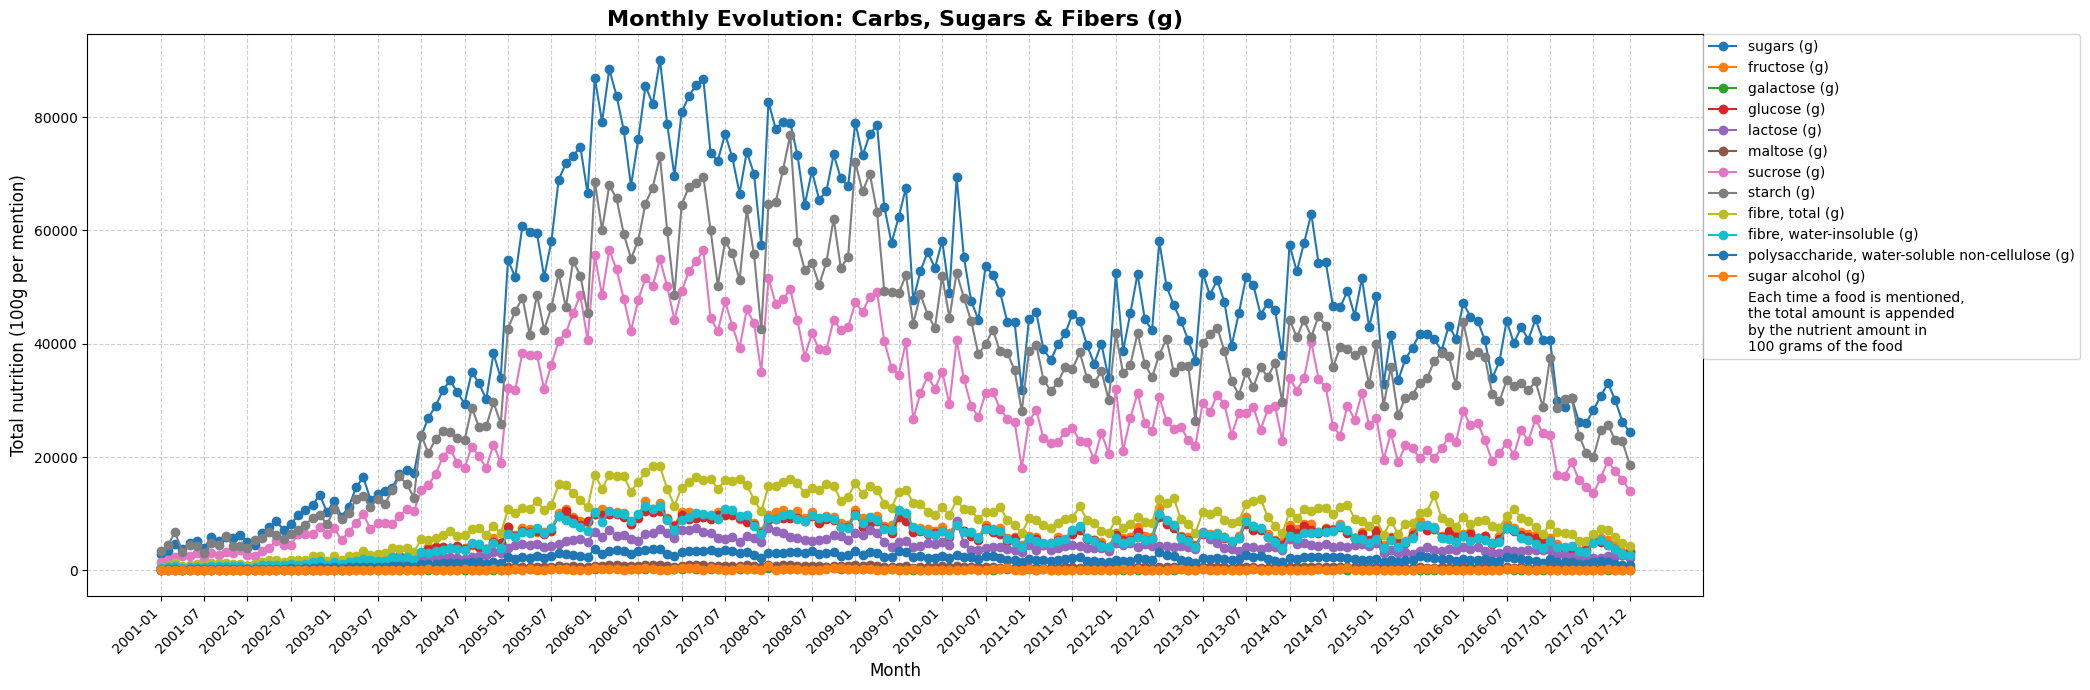

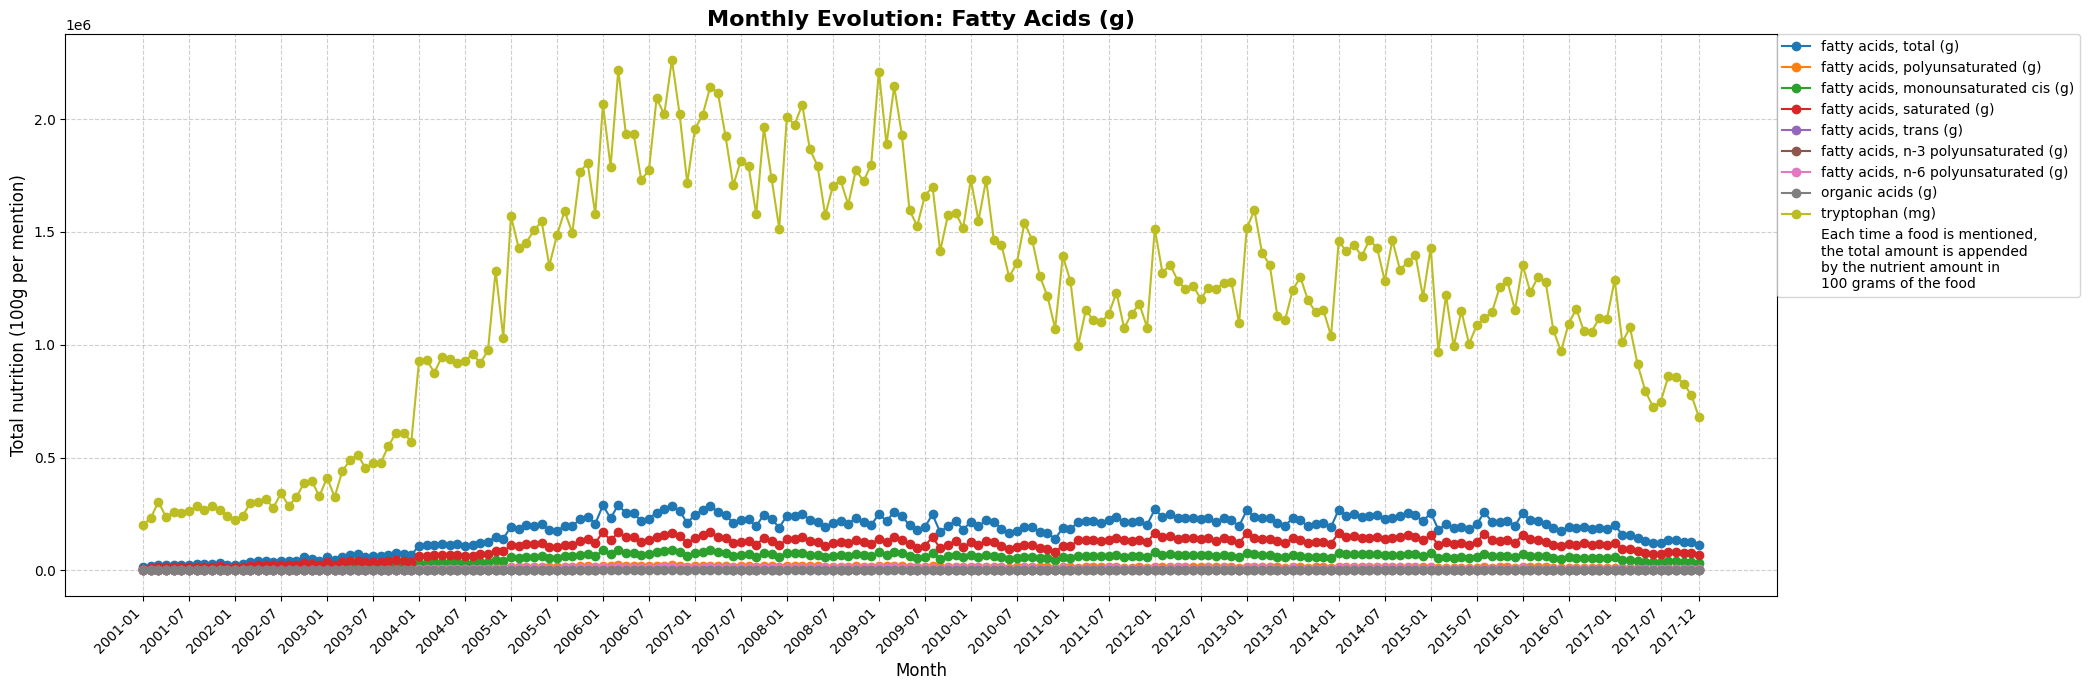

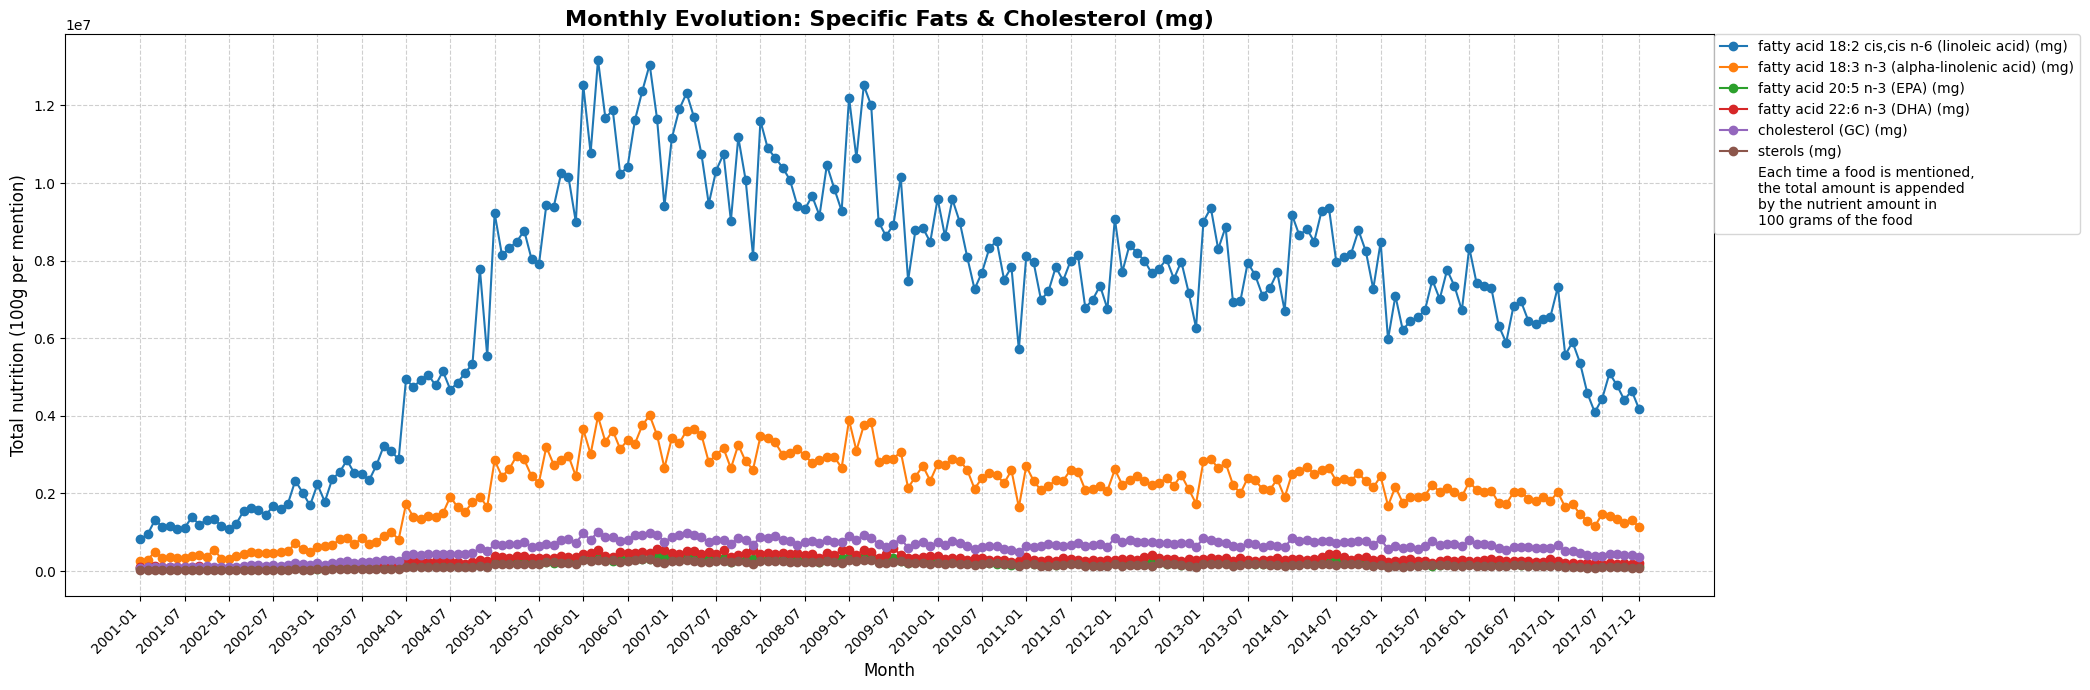

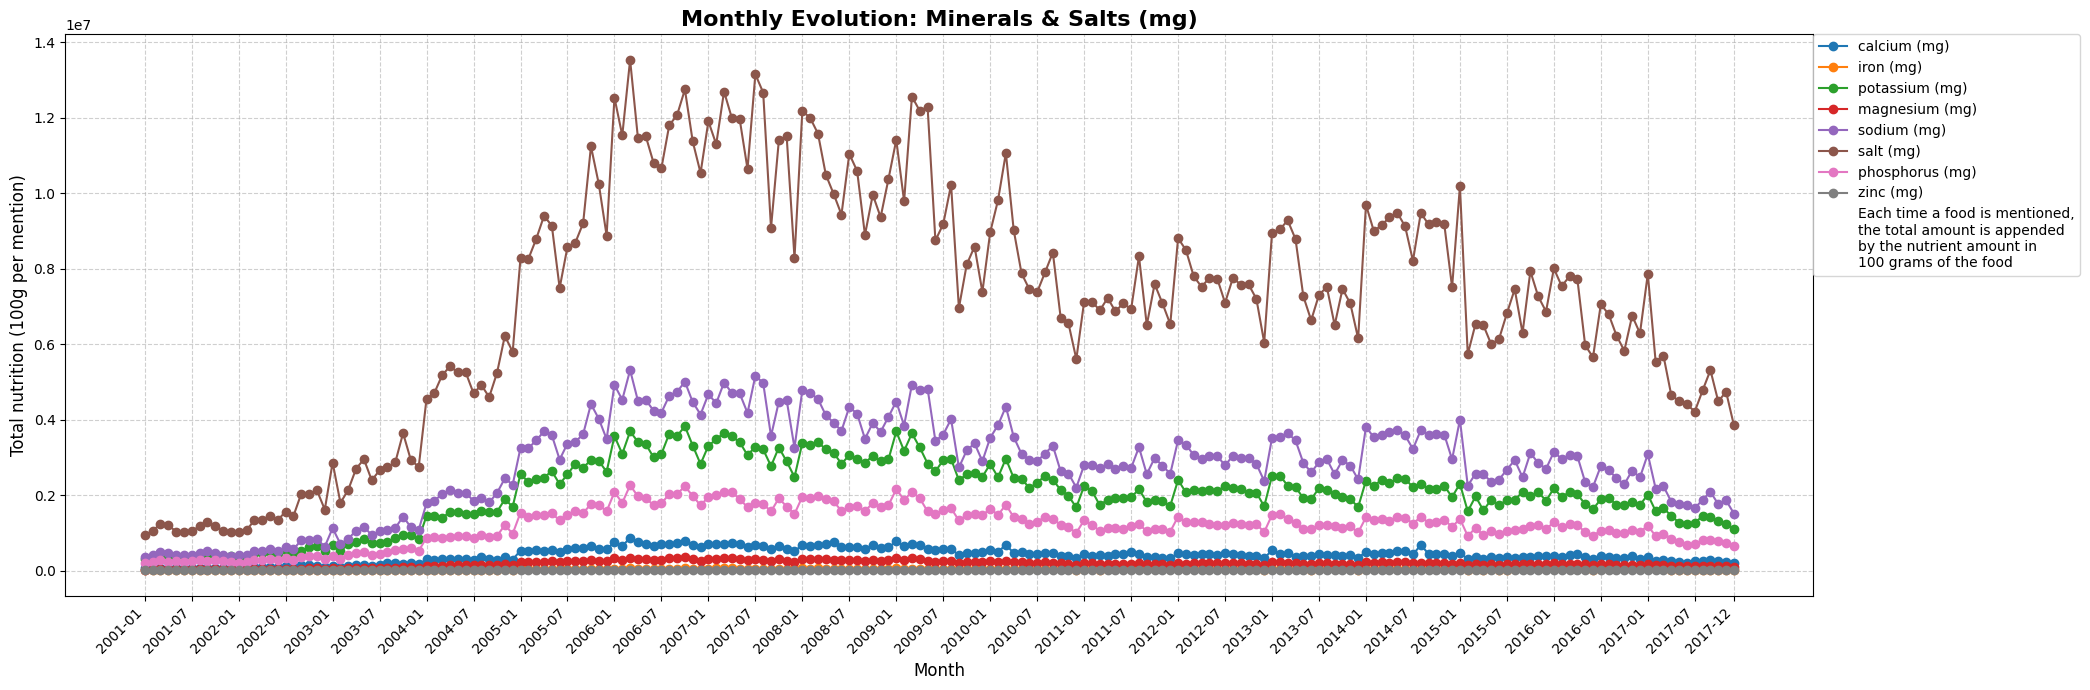

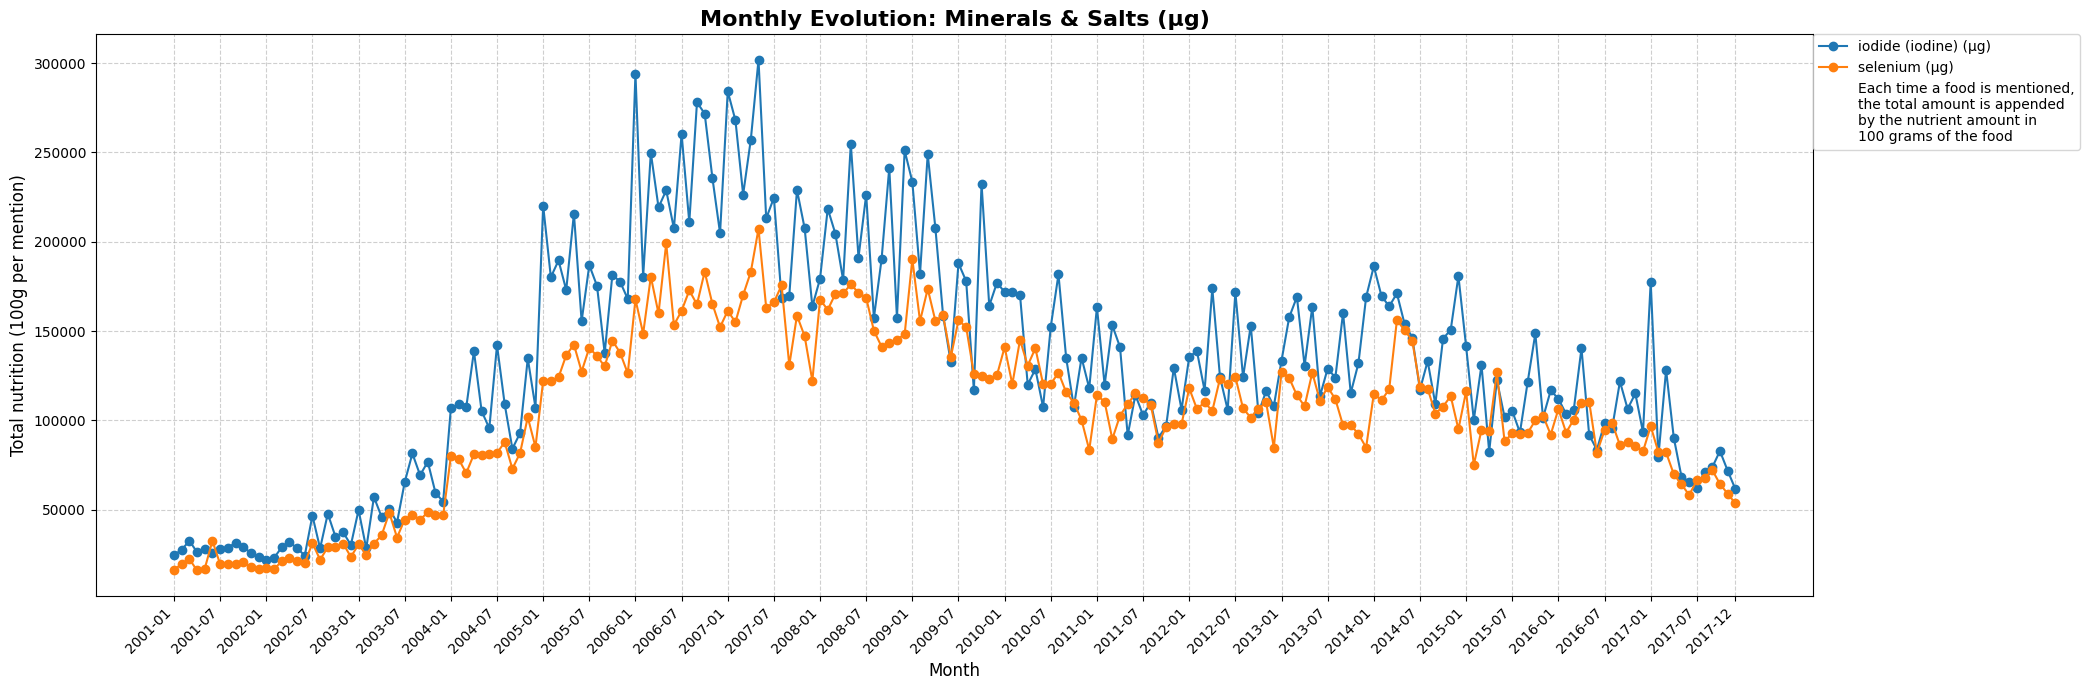

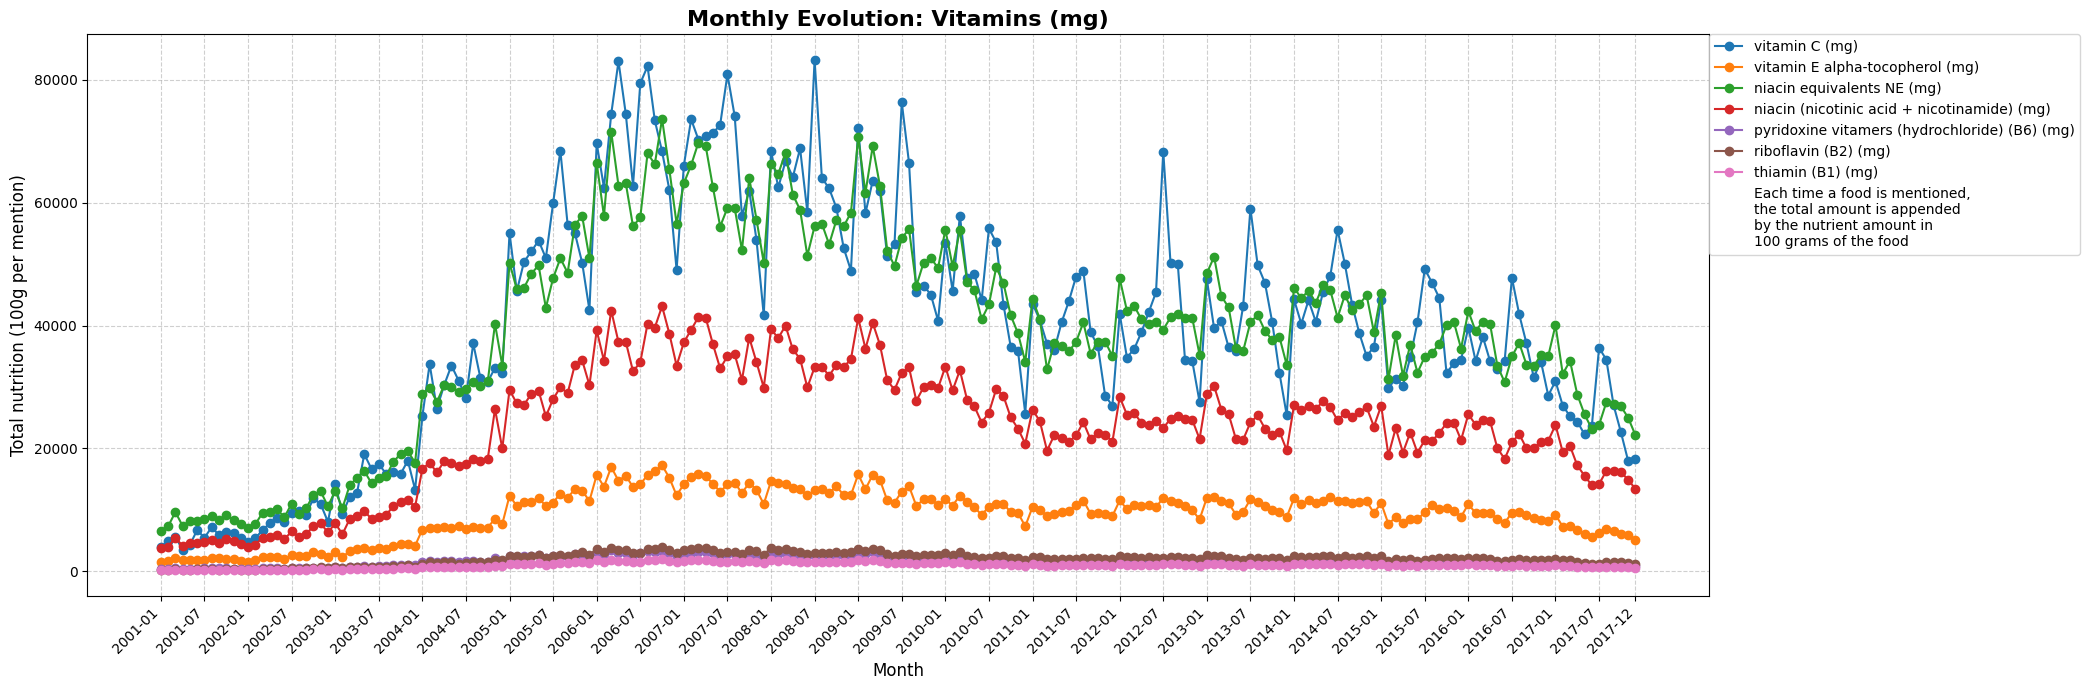

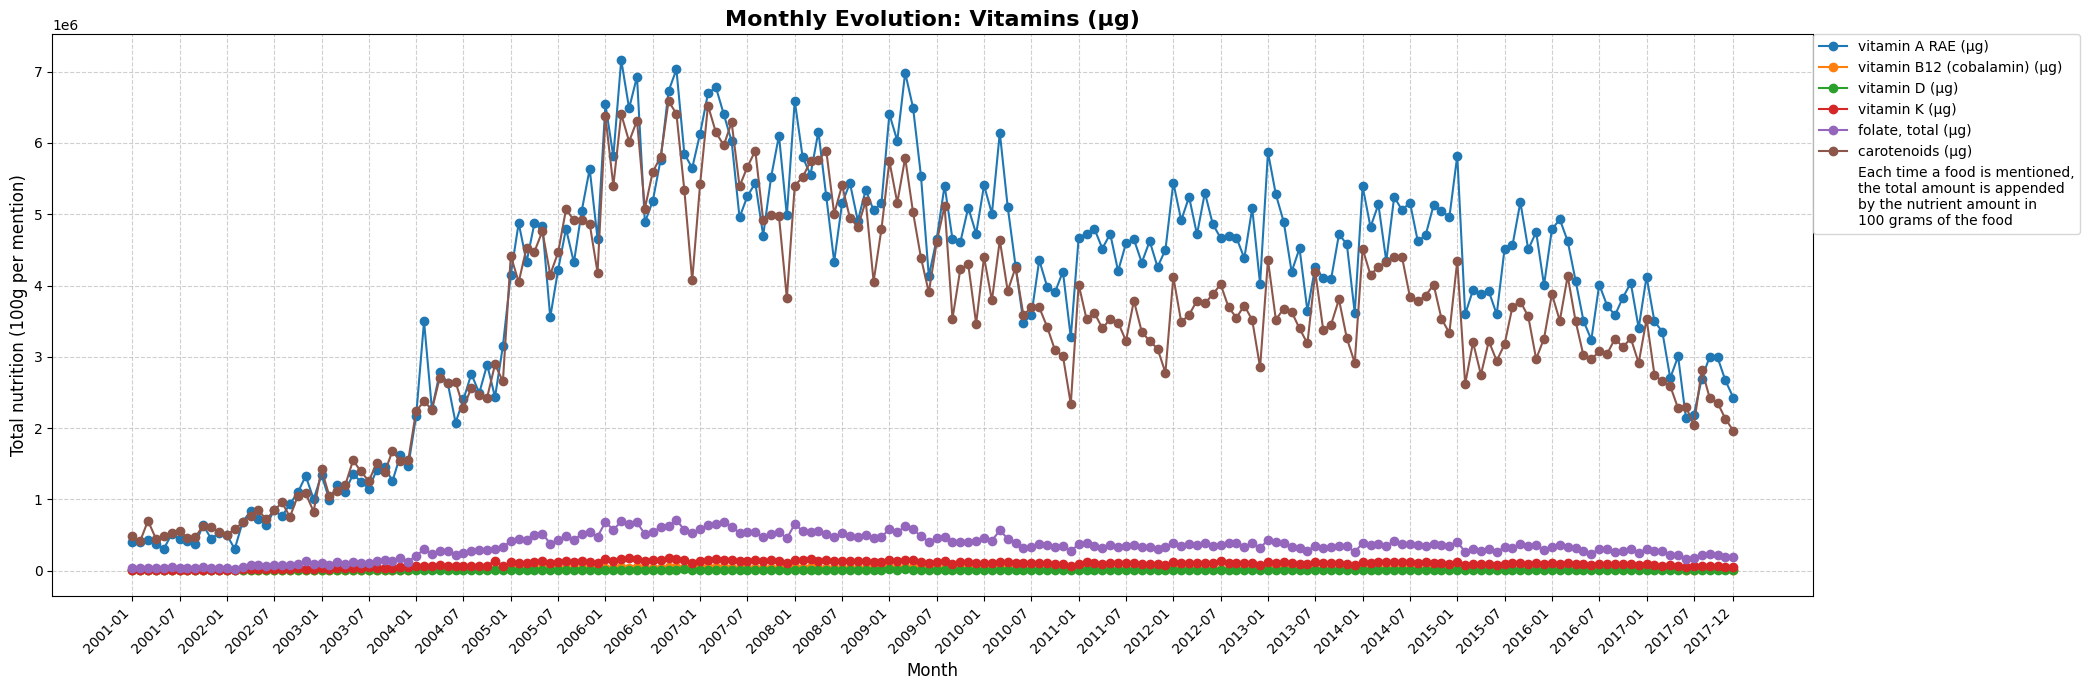

In [12]:
# Part 1) results

draw_monthly_nutrition_intake(monthly_nutrition_df)

In [13]:
# NOTE: Just some helpful prints for testing

# Look at one saved record
first_file = sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz")))[0]
with gzip.open(first_file, "rt", encoding="utf-8") as f:
    first = None
    for line in f:
        first = json.loads(line)
        break

# print(json.dumps(first, ensure_ascii=False, indent=2))

In [14]:
# NOTE: Just some helpful prints for testing

# print("\nDistinct foods found:", counts.shape[1])
# print(counts.sum().nlargest(25))

In [15]:
# NOTE: Just some helpful prints for testing

def show_fields():
    p = sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz")))[0]

    with gzip.open(p, "rt", encoding="utf-8") as f:
        next(f)
        next(f)
        next(f)
        # 4th in this dataset is a good example
        r = json.loads(next(f))

    print(r.keys())
    return r

# show_fields()

In [16]:
# Part 2)

def load_titles():
    rows = []
    for p in sorted(glob.glob(str(OUT_DIR / "*.jsonl.gz"))):
        with gzip.open(p, "rt", encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                rows.append((r["month"], r["date"], r["thread_id"],
                             r["title"], r["title_lemmas"], r["foods"], len(r["foods"])))
    return pd.DataFrame(rows, columns=["month", "date", "thread_id",
                                       "title", "title_lemmas", "foods", "n_foods"])


titles_df = load_titles()
# titles_df.to_csv("datasets/titles_by_month.csv.gz", index=False)
monthly_titles = {month: g for month, g in titles_df.groupby("month")}

print(len(titles_df), "titles in", len(monthly_titles), "months\n")
# print(monthly_titles[sorted(monthly_titles)[0]].head())

1237182 titles in 204 months



In [17]:
from afinn import Afinn
from scipy.stats import pearsonr

afinn = Afinn(language='fi')


def score_titles(df, column="title"):
    return pd.Series([afinn.score(t) for t in df[column]], index=df.index)


def monthly_sentiment_from_titles(titles_by_month, column="title"):
    rows = {}
    for month, df in titles_by_month.items():
        scores = score_titles(df, column)
        rows[month] = {
            "sentiment_sum": scores.sum(),
            "n_titles": len(df),
        }
    return pd.DataFrame.from_dict(rows, orient="index").sort_index()


monthly_sentiment = monthly_sentiment_from_titles(monthly_titles)


In [18]:
ENERGY_COL = 'energia, laskennallinen (kJ)'


def build_comparison(nutrition_df, sentiment_df, nutrient=ENERGY_COL):
    return sentiment_df.join(nutrition_df[[nutrient]].rename(columns={nutrient: "nutrition_sum"}),
                        how="inner")


def pearson_with_nutrition(comp, other_col):
    r, p = pearsonr(comp[other_col], comp["nutrition_sum"])
    return pd.DataFrame([{"series": other_col, "nutrition": "nutrition_sum",
                          "pearson_r": r, "p_value": p, "n_periods": len(comp)}])

comparison = build_comparison(monthly_nutrition_df, monthly_sentiment)

In [19]:
def plot_vs_nutrition(comp, other_col, other_name, other_axis_label,
                      other_color="tab:red", other_marker="s",
                      nutrition_label="Nutrition sum (energy, kJ)",
                      period_label="Monthly", x_label="Month"):
    x = pd.to_datetime(comp.index)
    r, p = pearsonr(comp[other_col], comp["nutrition_sum"])

    fig, ax1 = plt.subplots(figsize=(21, 7))

    ax1.plot(x, comp["nutrition_sum"], color="tab:green", marker="o", label=nutrition_label)
    ax1.set_xlabel(x_label)
    ax1.set_ylabel(nutrition_label, color="tab:green")
    ax1.tick_params(axis="y", labelcolor="tab:green")
    ax1.grid(True, linestyle="--", alpha=0.6)

    ax2 = ax1.twinx()
    ax2.plot(x, comp[other_col], color=other_color, marker=other_marker, label=other_axis_label)
    ax2.set_ylabel(other_axis_label, color=other_color)
    ax2.tick_params(axis="y", labelcolor=other_color)

    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")

    plt.title(f"{period_label} {other_name} vs. nutrition (Pearson r = {r:.3f}, p = {p:.3g})",
              fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

         sentiment_sum  n_titles  nutrition_sum
2001-01           -9.0       775   1.106156e+06
2001-02          -43.0       948   1.393052e+06
2001-03           22.0      1063   1.774585e+06
2001-04            1.0       957   1.560076e+06
2001-05           38.0      1056   1.673610e+06
...                ...       ...            ...
2017-08         -198.0      4007   7.815354e+06
2017-09         -101.0      3865   7.890702e+06
2017-10           71.0      3825   7.398551e+06
2017-11          -38.0      3631   7.155081e+06
2017-12           24.0      3385   6.554614e+06

[204 rows x 3 columns]
       series     nutrition  pearson_r      p_value  n_periods
sentiment_sum nutrition_sum  -0.337251 8.114665e-07        204


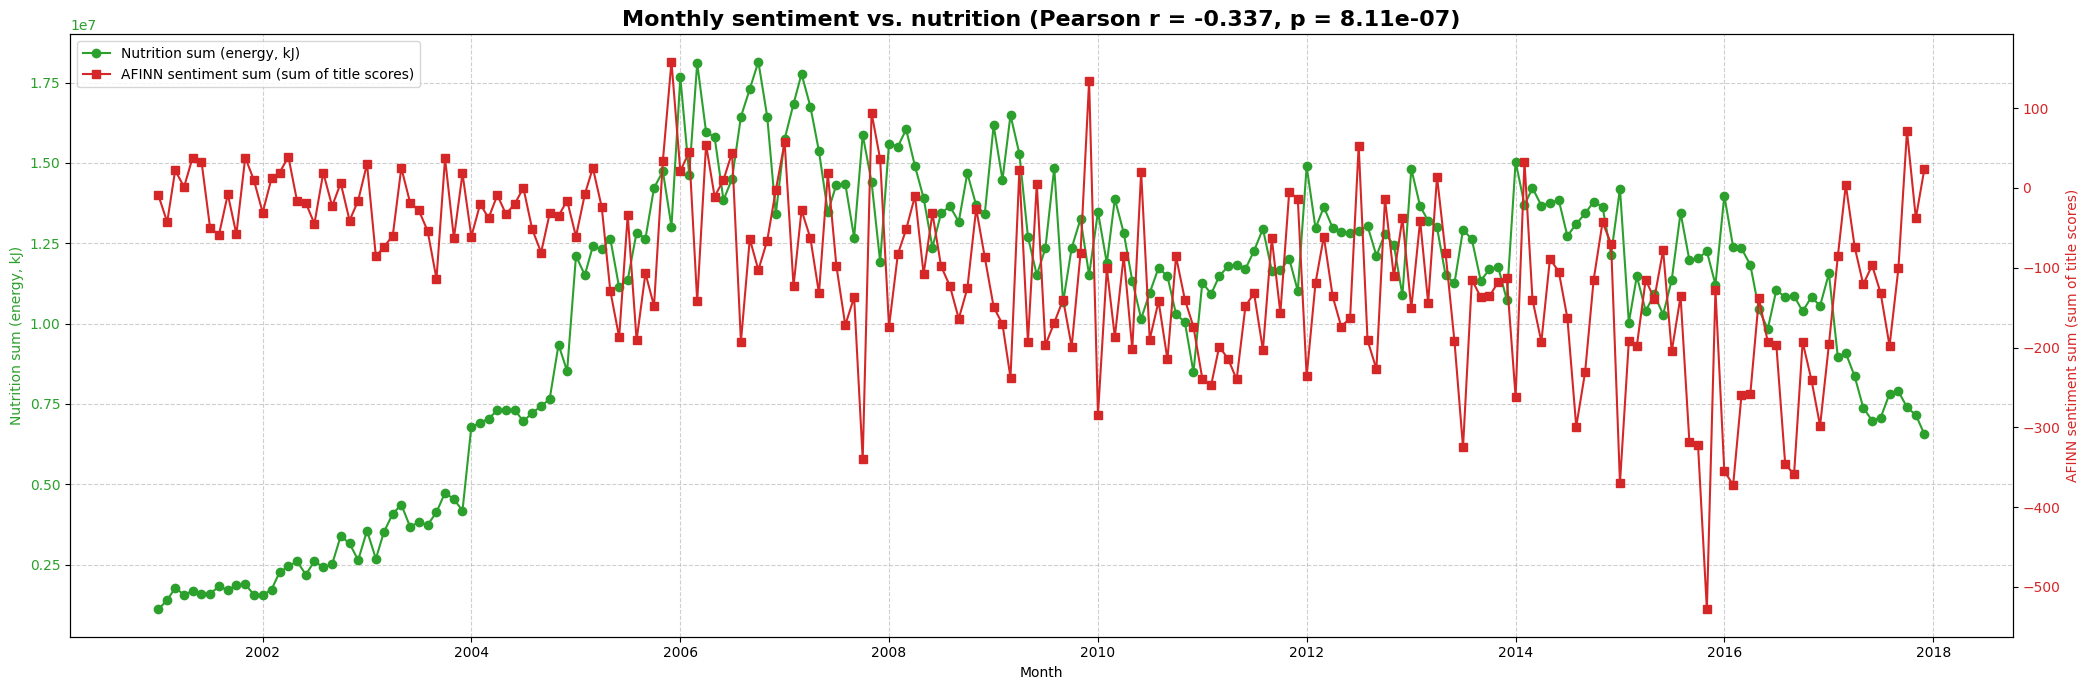

In [20]:
print(comparison)
print(pearson_with_nutrition(comparison, "sentiment_sum").to_string(index=False))
plot_vs_nutrition(comparison, "sentiment_sum", "sentiment", "AFINN sentiment sum (sum of title scores)")

      sentiment_sum  n_titles  nutrition_sum
2001          -85.0     12555   1.952680e+07
2002          -96.0     18734   2.946961e+07
2003         -388.0     30493   4.699087e+07
2004         -397.0     58013   8.978882e+07
2005         -672.0     95236   1.509350e+08
2006         -408.0    122252   1.922832e+08
2007         -888.0    116219   1.795255e+08
2008        -1083.0    110206   1.703669e+08
2009        -1377.0     98532   1.616222e+08
2010        -1786.0     78866   1.365537e+08
2011        -1861.0     71813   1.405467e+08
2012        -1417.0     76610   1.543210e+08
2013        -1540.0     73454   1.484966e+08
2014        -1677.0     81174   1.630746e+08
2015        -2730.0     73789   1.395533e+08
2016        -3210.0     70231   1.352908e+08
2017         -944.0     49005   9.621811e+07
       series     nutrition  pearson_r  p_value  n_periods
sentiment_sum nutrition_sum  -0.450882   0.0693         17


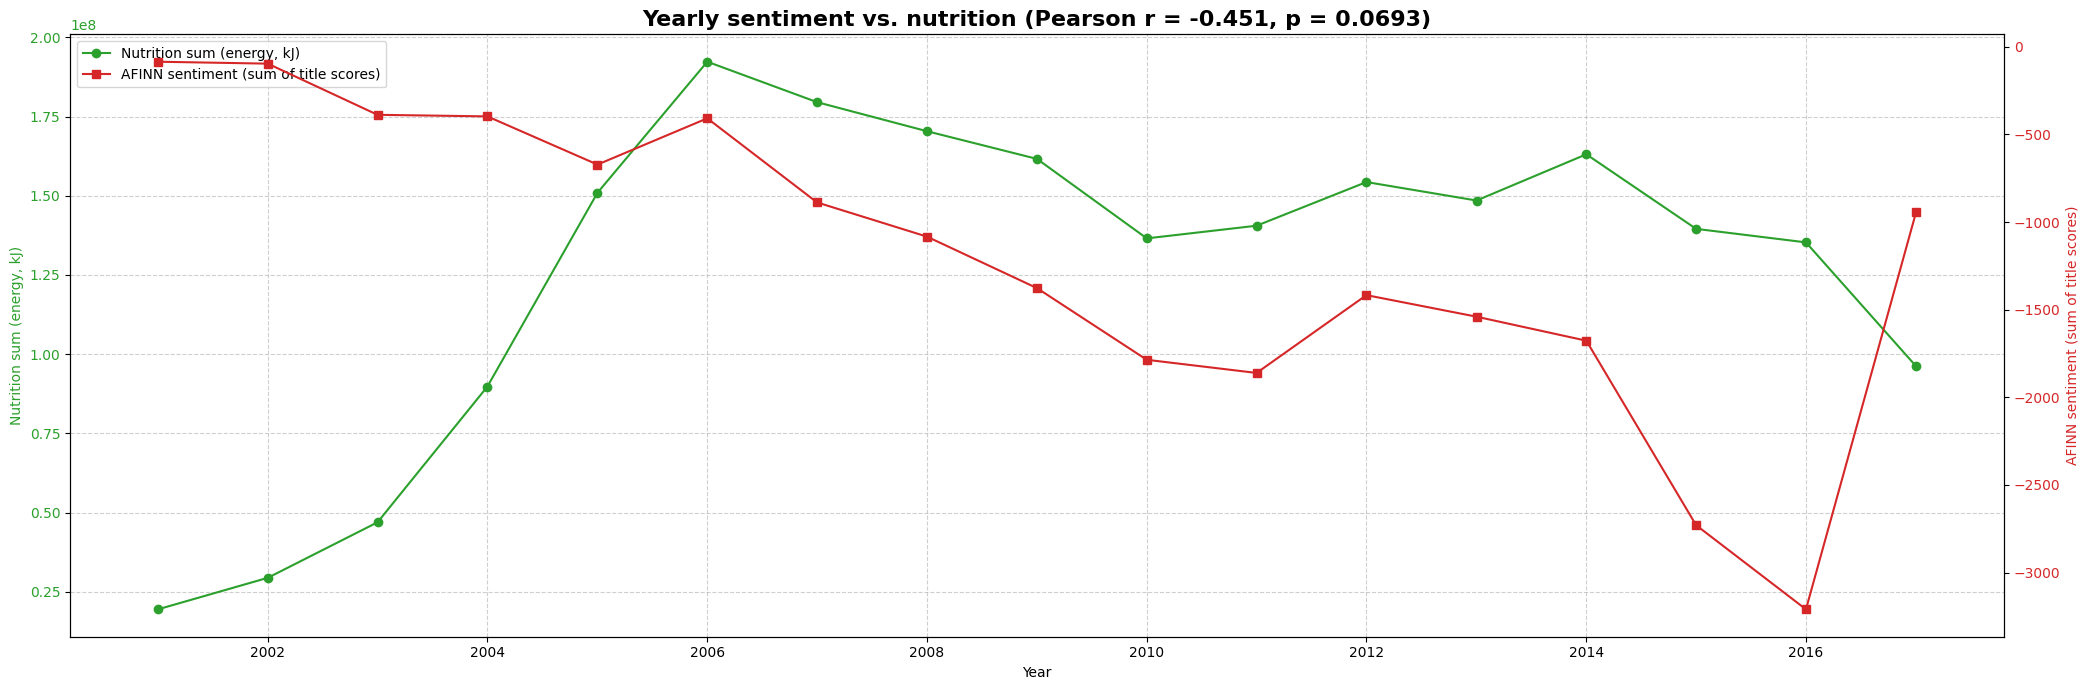

In [21]:
# part 3)
yearly_sentiment = monthly_sentiment.groupby(monthly_sentiment.index.str[:4]).sum()
yearly_nutrition = monthly_nutrition_df.groupby(monthly_nutrition_df.index.str[:4]).sum()

yearly_comparison = build_comparison(yearly_nutrition, yearly_sentiment)
print(yearly_comparison)
print(pearson_with_nutrition(yearly_comparison, "sentiment_sum").to_string(index=False))
plot_vs_nutrition(yearly_comparison, "sentiment_sum", "sentiment", "AFINN sentiment (sum of title scores)",
                  period_label="Yearly", x_label="Year")

In [22]:
# part 4)
def diversity_from_counts(counts_df):
    return (counts_df > 0).sum(axis=1).to_frame("n_distinct_foods")

monthly_diversity = diversity_from_counts(counts)

# Produces single dataframe with no duplicate foods for years
# 2001_1 {"kala": 2, "kani": 1}, 2001_2 {"ankka": 1, "kani": 3}, ...
# -> 2001 {"ankka": 1, "kala": 2, "kani": 4}
yearly_counts = counts.groupby(counts.index.str[:4]).sum()

# counts distinct foods
yearly_diversity = diversity_from_counts(yearly_counts)

         n_distinct_foods  nutrition_sum
month                                   
2001-01               138   1.106156e+06
2001-02               136   1.393052e+06
2001-03               164   1.774585e+06
2001-04               136   1.560076e+06
2001-05               141   1.673610e+06
...                   ...            ...
2017-08               307   7.815354e+06
2017-09               297   7.890702e+06
2017-10               282   7.398551e+06
2017-11               287   7.155081e+06
2017-12               279   6.554614e+06

[204 rows x 2 columns]
          series     nutrition  pearson_r      p_value  n_periods
n_distinct_foods nutrition_sum   0.939455 6.620091e-96        204


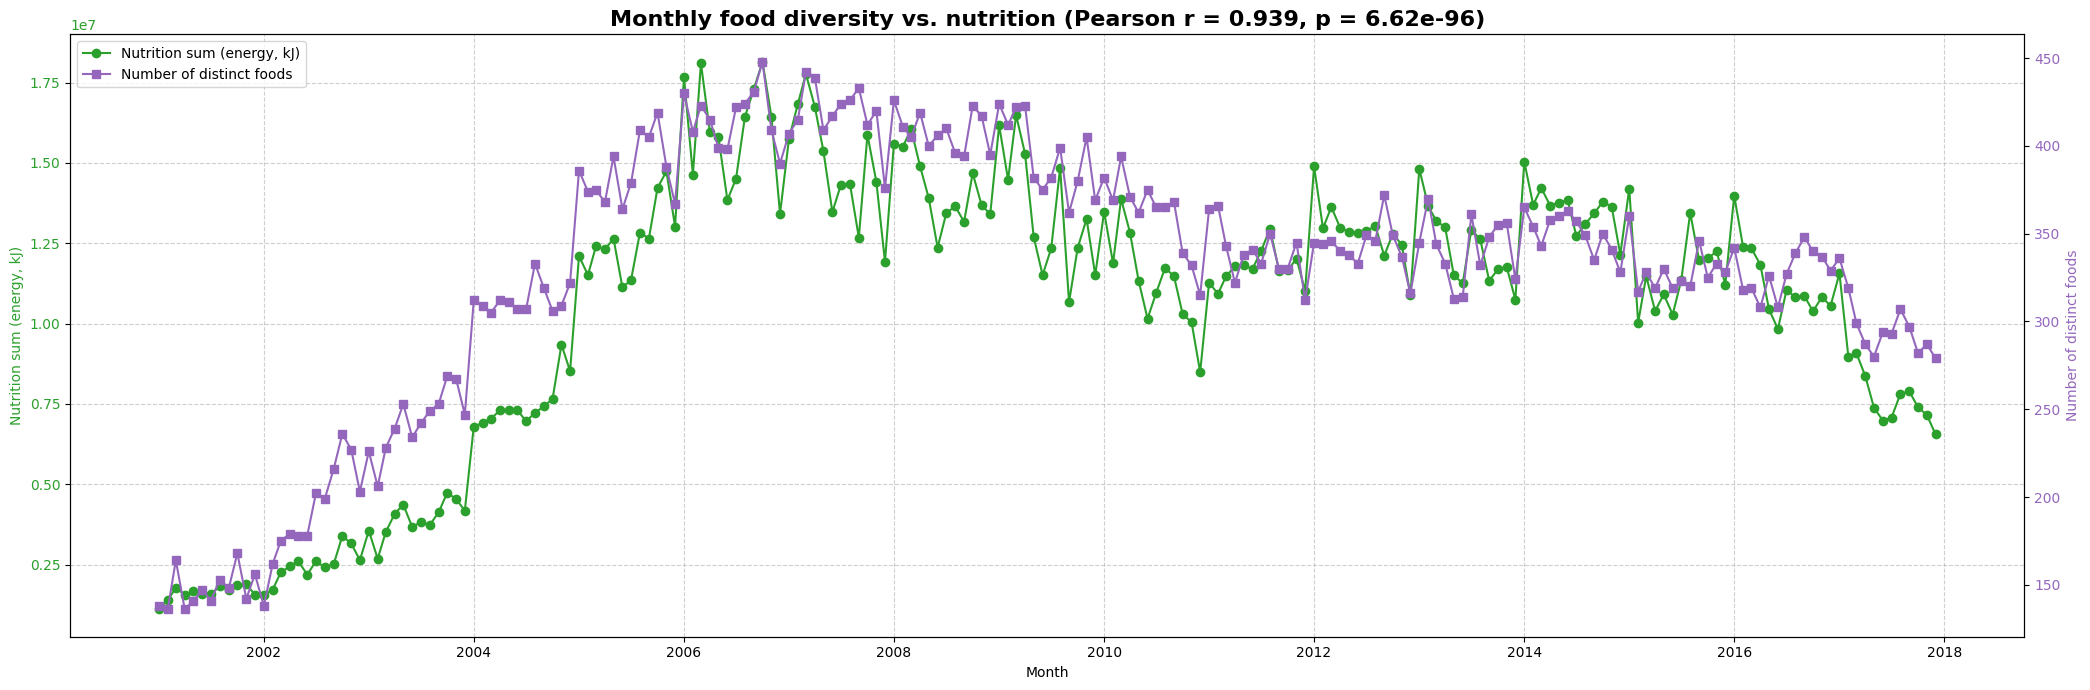

In [23]:
# Monthly
monthly_diversity_comparison = build_comparison(monthly_nutrition_df, monthly_diversity)
print(monthly_diversity_comparison)
print(pearson_with_nutrition(monthly_diversity_comparison, "n_distinct_foods").to_string(index=False))
plot_vs_nutrition(monthly_diversity_comparison, "n_distinct_foods", "food diversity", "Number of distinct foods",
                  other_color="tab:purple")

       n_distinct_foods  nutrition_sum
month                                 
2001                340   1.952680e+07
2002                434   2.946961e+07
2003                490   4.699087e+07
2004                572   8.978882e+07
2005                661   1.509350e+08
2006                674   1.922832e+08
2007                691   1.795255e+08
2008                673   1.703669e+08
2009                672   1.616222e+08
2010                619   1.365537e+08
2011                615   1.405467e+08
2012                614   1.543210e+08
2013                623   1.484966e+08
2014                618   1.630746e+08
2015                600   1.395533e+08
2016                593   1.352908e+08
2017                555   9.621811e+07
          series     nutrition  pearson_r      p_value  n_periods
n_distinct_foods nutrition_sum   0.953005 3.512781e-09         17


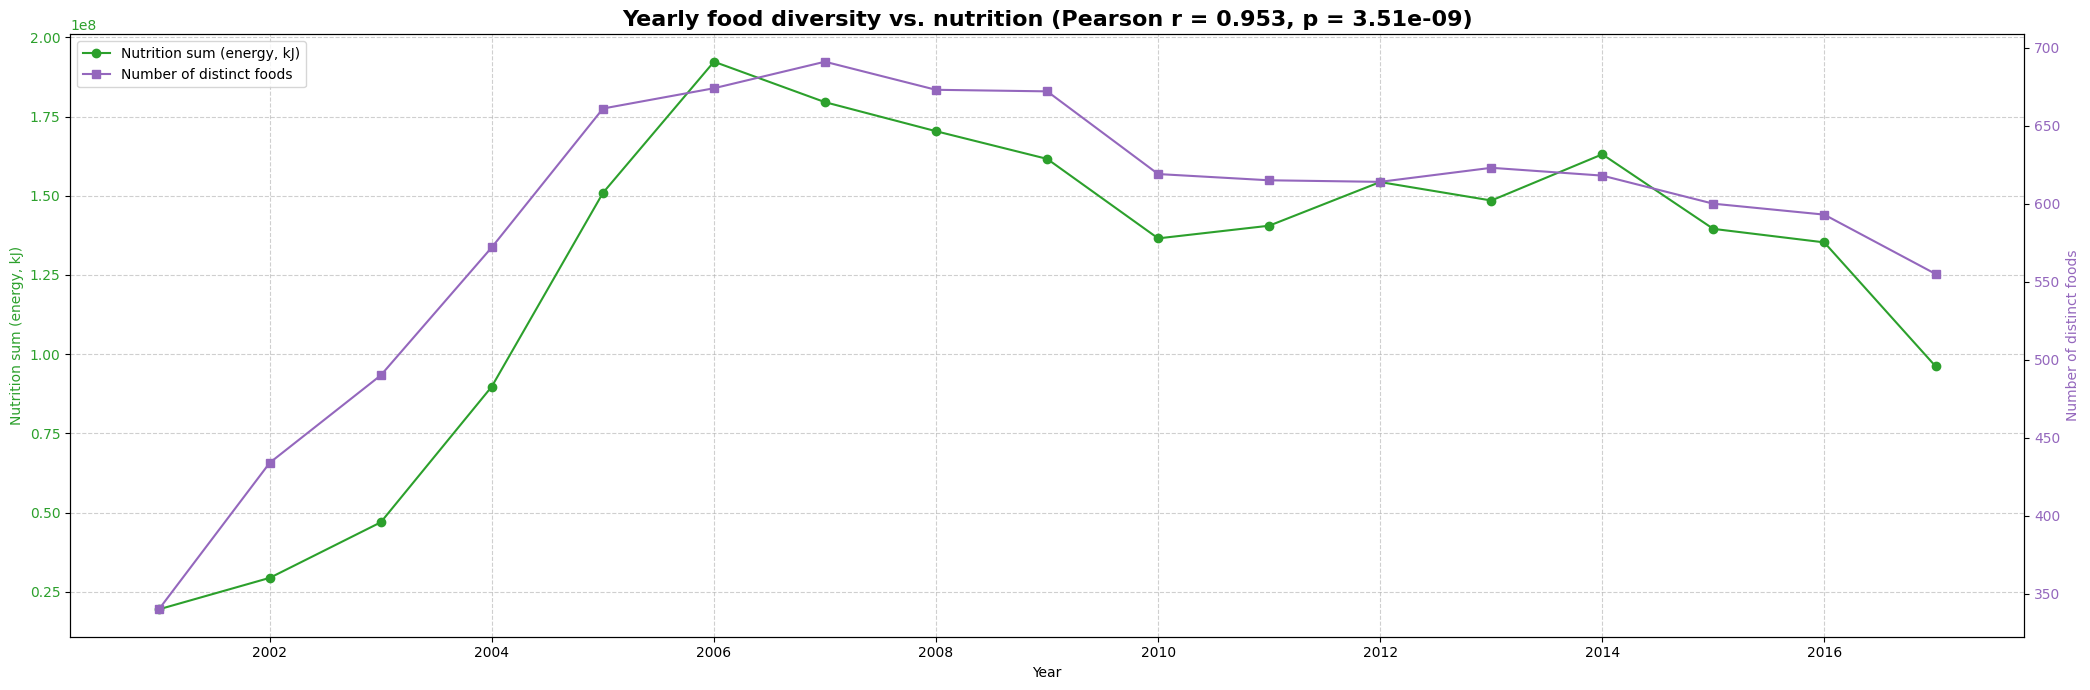

In [24]:
# Yearly
yearly_diversity_comparison = build_comparison(yearly_nutrition, yearly_diversity)
print(yearly_diversity_comparison)
print(pearson_with_nutrition(yearly_diversity_comparison, "n_distinct_foods").to_string(index=False))
plot_vs_nutrition(yearly_diversity_comparison, "n_distinct_foods", "food diversity", "Number of distinct foods",
                  other_color="tab:purple", period_label="Yearly", x_label="Year")

               series     nutrition  pearson_r      p_value  n_periods
n_distinct_categories nutrition_sum   0.561842 2.273333e-18        204


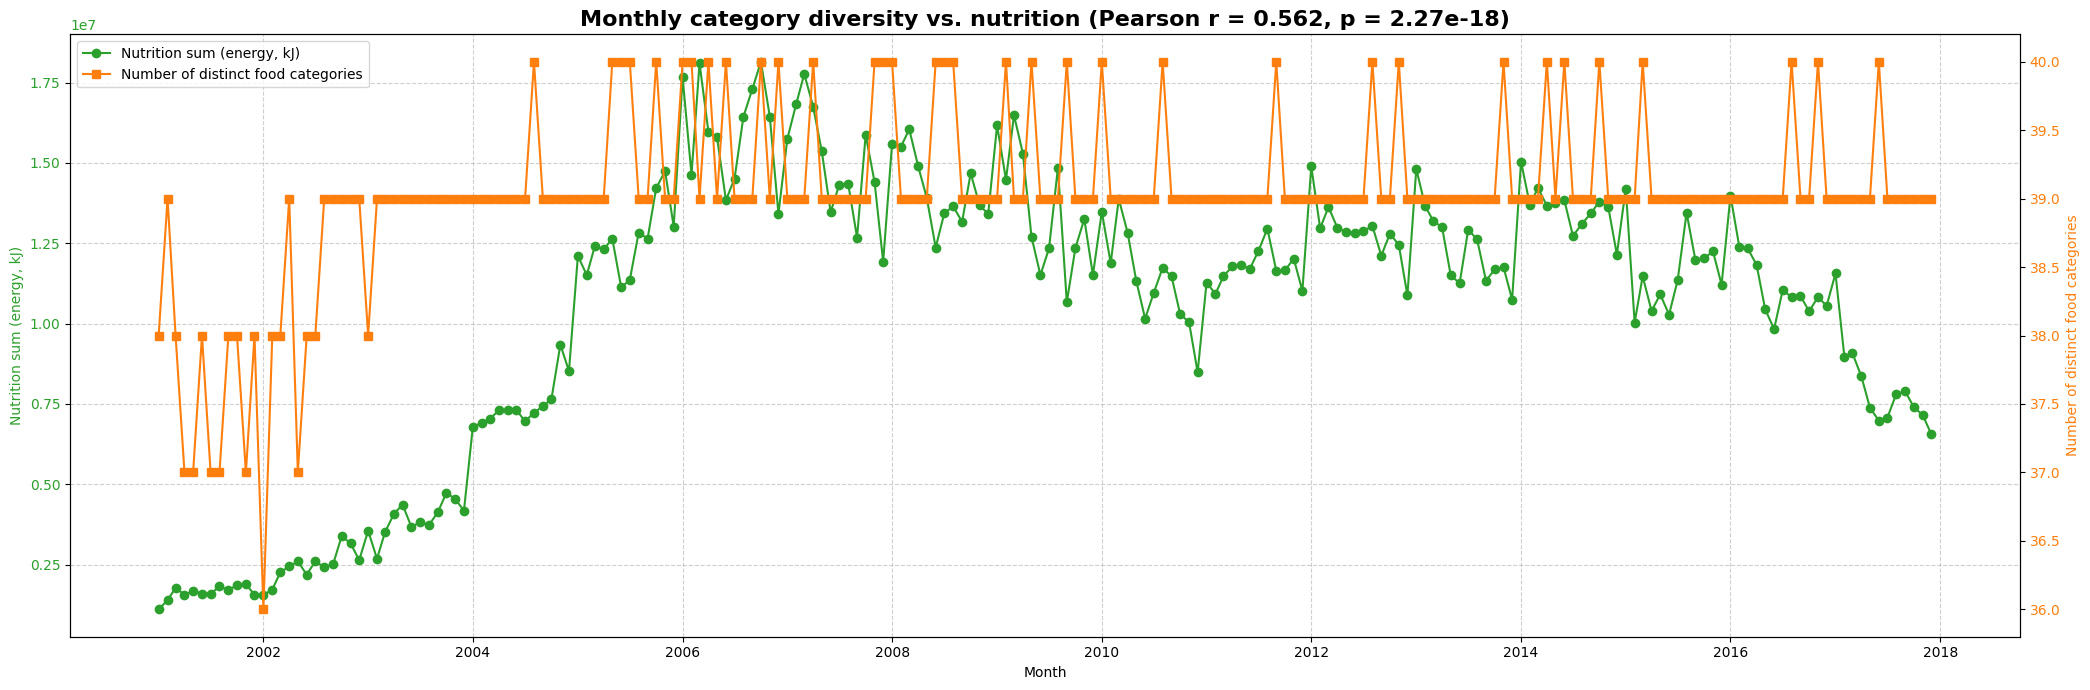

               series     nutrition  pearson_r  p_value  n_periods
n_distinct_categories nutrition_sum   0.867218 0.000007         17


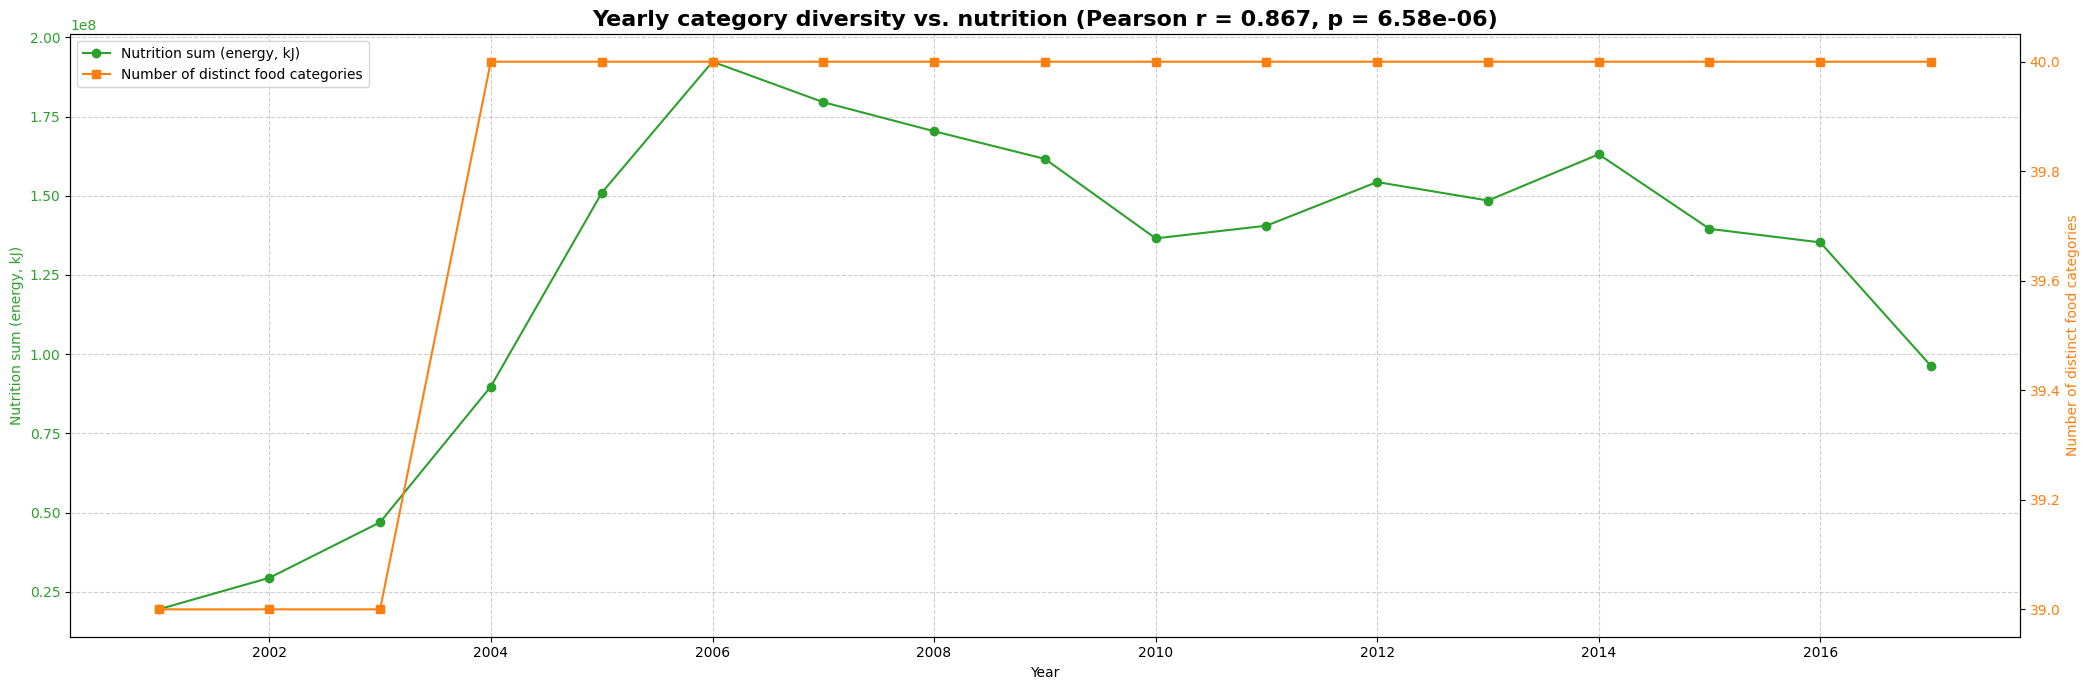

In [25]:
# Task 5
Fineli_with_category = Path("datasets/fineli_categories_40.xlsx")

food_categories = pd.read_excel(Fineli_with_category, index_col=0)["kategoria"]
food_categories = food_categories[~food_categories.index.duplicated(keep="first")]

cat_of_food = food_categories.reindex(counts.columns).values
counts_by_category = counts.T.groupby(cat_of_food).sum().T
yearly_counts_by_category = counts_by_category.groupby(counts_by_category.index.str[:4]).sum()

def category_diversity(cat_counts):
    """number of distinct categories mentioned in the period"""
    return (cat_counts > 0).sum(axis=1).to_frame("n_distinct_categories")

monthly_cat_div = category_diversity(counts_by_category)
yearly_cat_div  = category_diversity(yearly_counts_by_category)

# by month
for col, label in [("n_distinct_categories", "Number of distinct food categories")]:
    comp = build_comparison(monthly_nutrition_df, monthly_cat_div[[col]])
    print(pearson_with_nutrition(comp, col).to_string(index=False))
    plot_vs_nutrition(comp, col, "category diversity", label, other_color="tab:orange")

# by year
for col, label in [("n_distinct_categories", "Number of distinct food categories")]:
    comp = build_comparison(yearly_nutrition, yearly_cat_div[[col]])
    print(pearson_with_nutrition(comp, col).to_string(index=False))
    plot_vs_nutrition(comp, col, "category diversity", label, other_color="tab:orange",
                      period_label="Yearly", x_label="Year")


In [26]:
# Part 6)
def calculate_vocabulary_growth(titles_df):
    df = titles_df[["month", "title"]].dropna().copy()

    df["tokens"] = df["title"].map(word_tokenize)
    df["n_tokens"] = df["tokens"].str.len()

    # Aggregate token counts and token lists per month
    monthly = (
        df.groupby("month")
        .agg(
            total_tokens=("n_tokens", "sum"),
            tokens=("tokens", lambda s: [
                lemmatize_word(token.lower()) for title_tokens in s for token in title_tokens
            ])
        )
        .sort_index()
    )

    # Cumulative token count and vocabulary size
    monthly["total_tokens"] = monthly["total_tokens"].cumsum()

    monthly["vocabulary_size"] = (
        monthly["tokens"]
        .map(set)
        .map(lambda _: 0)
    )

    vocabulary = set()
    vocabulary_sizes = []

    for tokens in monthly["tokens"]:
        vocabulary.update(tokens)
        vocabulary_sizes.append(len(vocabulary))

    monthly["vocabulary_size"] = vocabulary_sizes

    return monthly.drop(columns="tokens").reset_index()


vocabulary_df = calculate_vocabulary_growth(titles_df)

display(vocabulary_df)

,month,total_tokens,vocabulary_size
0,2001-01,2971,1277
1,2001-02,6795,2516
2,2001-03,10847,3660
3,2001-04,14395,4536
4,2001-05,18180,5429
...,...,...,...
199,2017-08,4387480,379332
200,2017-09,4403961,380432
201,2017-10,4420098,381525
202,2017-11,4435360,382555


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [28]:
# Remove invalid observations before taking logarithms
fit_df = vocabulary_df[
    (vocabulary_df["total_tokens"] > 0)
    & (vocabulary_df["vocabulary_size"] > 0)
].copy()

X = np.log(fit_df[["total_tokens"]].to_numpy())
y = np.log(fit_df["vocabulary_size"].to_numpy())

model = LinearRegression()
model.fit(X, y)

log_K = model.intercept_
K = np.exp(log_K)
beta = model.coef_[0]

y_pred = model.predict(X)

r_squared = r2_score(y, y_pred)

n = len(y)
p = 1

adjusted_r_squared = (
    1-(1-r_squared) * (n-1) / (n-p-1)
)

print(f"Heap's law: V(N) = {K:.4f} * N^{beta:.4f}")
print(f"K: {K:.4f}")
print(f"Beta: {beta:.4f}")
print(f"R-squared (log space): {r_squared:.4f}")
print(f"Adjusted R-squared (log space): {adjusted_r_squared:.4f}")

Heap's law: V(N) = 2.6583 * N^0.7761
K: 2.6583
Beta: 0.7761
R-squared (log space): 1.0000
Adjusted R-squared (log space): 1.0000


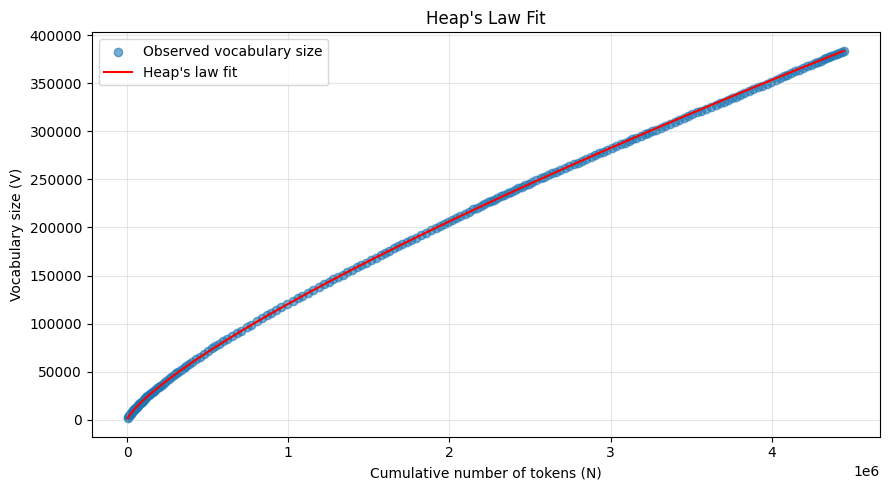

In [29]:
N = fit_df["total_tokens"].to_numpy()
V = fit_df["vocabulary_size"].to_numpy()

# Fitted values in the original scale
V_pred = K * N**beta

plt.figure(figsize=(9, 5))

plt.scatter(N, V, label="Observed vocabulary size", alpha=0.6)
plt.plot(N, V_pred, label="Heap's law fit", color="red")

plt.xlabel("Cumulative number of tokens (N)")
plt.ylabel("Vocabulary size (V)")
plt.title("Heap's Law Fit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
# Part 7)
df = titles_df.loc[titles_df["title"].notna(), ["title"]].copy()
df["title_length"] = df["title"].str.len()

# 20-bin subdivision
df["length_bin"] = pd.cut(df["title_length"], bins=20)

bin_frequencies = (
    df.groupby("length_bin", observed=False)
    .size()
    .reset_index(name="frequency")
)

In [31]:
ranked = (
    bin_frequencies
    .sort_values("frequency", ascending=False)
    .reset_index(drop=True)
)

ranked["rank"] = np.arange(1, len(ranked) + 1)

fit_df = ranked[ranked["frequency"] > 0].copy()

# Fit log(frequency) = log(C) - s * log(rank)
X = np.log(fit_df[["rank"]].to_numpy())
y = np.log(fit_df["frequency"].to_numpy())

model = LinearRegression()
model.fit(X, y)

C = np.exp(model.intercept_)
s = -model.coef_[0]

y_pred = model.predict(X)

r_squared = r2_score(y, y_pred)

n = len(y)
p = 1

adjusted_r_squared = (
    1 - (1 - r_squared) * (n - 1) / (n - p - 1)
    if n > p + 1 else np.nan
)

print(f"Zipf's law: f(r) = {C:.4f} * r^(-{s:.4f})")
print(f"Exponent (s): {s:.4f}")
print(f"R-squared: {r_squared:.4f}")
print(f"Adjusted R-squared: {adjusted_r_squared:.4f}")

display(ranked[["rank", "length_bin", "frequency"]])

Zipf's law: f(r) = 23898246.3119 * r^(-4.4847)
Exponent (s): 4.4847
R-squared: 0.7326
Adjusted R-squared: 0.7178


,rank,length_bin,frequency
0,1,"(12.8, 19.2]",311266
1,2,"(19.2, 25.6]",246574
2,3,"(25.6, 32.0]",207176
3,4,"(6.4, 12.8]",172169
4,5,"(32.0, 38.4]",110232
5,6,"(38.4, 44.8]",68357
6,7,"(44.8, 51.2]",53536
7,8,"(-0.128, 6.4]",40917
8,9,"(51.2, 57.6]",12840
9,10,"(57.6, 64.0]",12292


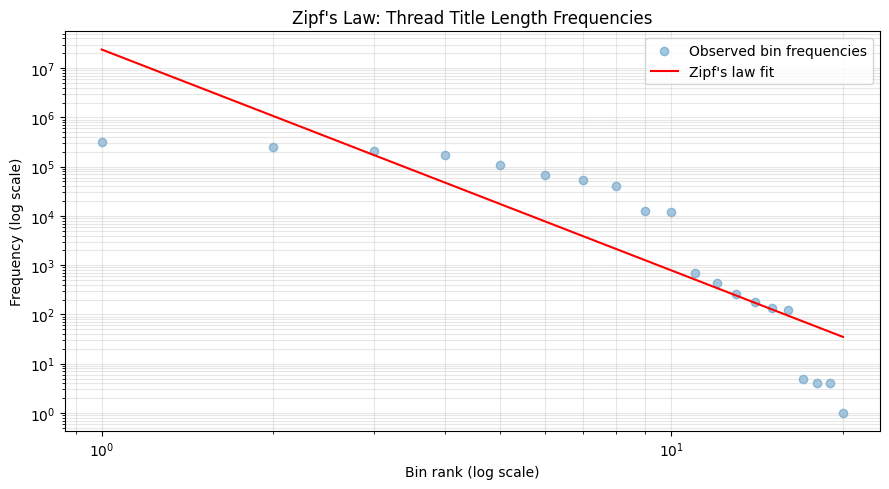

In [32]:
fitted_frequency = C * fit_df["rank"].to_numpy() ** (-s)

plt.figure(figsize=(9, 5))

plt.scatter(
    fit_df["rank"],
    fit_df["frequency"],
    label="Observed bin frequencies",
    alpha=0.4
)

plt.plot(
    fit_df["rank"],
    fitted_frequency,
    color="red",
    label="Zipf's law fit"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Bin rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Zipf's Law: Thread Title Length Frequencies")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Part 8)
from ollama import Client
from tqdm.auto import tqdm
import time
import hashlib

SENTIMENTS = ["liked", "disliked", "neutral", "uncertain"]

BATCH_SCHEMA = {
    "type": "object",
    "properties": {
        "results": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "classifications": {
                        "type": "array",
                        "items": {
                            "type": "object",
                            "properties": {
                                "food": {"type": "string"},
                                "sentiment": {
                                    "type": "string",
                                    "enum": SENTIMENTS,
                                },
                            },
                            "required": ["food", "sentiment"],
                        },
                    },
                },
                "required": ["classifications"],
            },
        },
    },
    "required": ["results"],
}

SINGLE_SCHEMA = {
    "type": "object",
    "properties": {
        "classifications": BATCH_SCHEMA["properties"]["results"]["items"]
            ["properties"]["classifications"],
    },
    "required": ["classifications"],
}

SYSTEM_PROMPT = """
You are annotating Finnish-language online forum messages.

For each supplied food, determine the author's expressed personal
preference toward consuming that food, based only on the message.

Sentiment labels:
- liked: The author clearly expresses liking, enjoyment, preference,
  or positive evaluation of the food.
- disliked: The author clearly expresses dislike, aversion,
  or negative evaluation of the food.
- neutral: The food is mentioned, eaten, discussed, or described
  without a clear positive or negative preference.
- uncertain: There is not enough reliable evidence to decide.

Rules:
1. Understand Finnish negation, inflection, colloquial language, and context.
2. Distinguish the author's own opinion from quoted speech or another
   person's opinion.
3. Do not infer dislike from a statement that a food is unhealthy.
4. Do not infer liking merely because the author eats or mentions a food.
5. A food can be liked even when its health effects are criticized.
6. Classify every supplied food independently.
7. Do not invent foods or add foods absent from the supplied list.
8. Do not assume that a general statement applies to every food mentioned.
9. Return exactly one classification for every supplied food.
10. Preserve the supplied food names exactly.
"""

MODEL_NAME = "qwen3:1.7b"
BATCH_SIZE = 5
# Ollama runs locally here
client = Client(host="http://localhost:11434")

def load_food_messages():
    """Load messages containing FINELI-matched foods."""
    rows = []

    for path in glob.glob(str(OUT_DIR / "*.jsonl.gz")):
        with gzip.open(path, "rt", encoding="utf-8") as file:
            for line in file:
                thread = json.loads(line)

                for msg in thread.get("messages", []):
                    foods = msg.get("foods", {})
                    text = msg.get("text", "").strip()
                    date = msg.get("date") or thread.get("date")

                    if text and foods and date:
                        rows.append({
                            "date": date,
                            "text": text,
                            "foods": foods,
                        })

    df = pd.DataFrame(rows)

    if df.empty:
        raise ValueError("No food-containing messages found in the parsed files.")

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.dropna(subset=["date"]).reset_index(drop=True)
    df["year"] = df["date"].dt.year

    return df

C:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
food_messages_df = load_food_messages()

In [18]:
display(food_messages_df.head())
print(f"Messages: {len(food_messages_df):,}")

,date,text,foods,year
0,2001-01-09,Lupasin itselleni kesään mennessä siirtyä kalj...,{'kalja': 1},2001
1,2001-01-01,Virikkeitä kanille ?,{'kani': 1},2001
2,2001-01-01,"Muutes , et kyllä saanut maailman ihaninta kan...",{'kani': 1},2001
3,2001-01-04,joops ... . mulla itelläni on ollut kolme kani...,"{'kani': 1, 'kala': 1}",2001
4,2001-01-07,"Laatikot on hyvä idea , ainakin mun kanit raka...",{'kani': 1},2001


Messages: 1,988,660


In [19]:
CACHE_PATH = OUT_DIR / "food_sentiment_LLM_results.jsonl"
print(f"{food_messages_df.memory_usage(deep=True).sum() / 1000000} MB")

733.62698 MB


In [20]:
def classify_foods_batch(batch):
    """Classify multiple independent messages in one request."""

    user_prompt = f"""
Classify the author's preference toward each supplied food.

There are {len(batch)} messages.
You MUST return exactly {len(batch)} result objects.

Each input message requires exactly one corresponding output object.
The output order MUST match the input order.

For each message:
- Classify every supplied food exactly once.
- Copy food names character-for-character.
- Do not add or omit foods.
- Do not combine messages.
- Do not use information from other messages.

Messages:
{json.dumps(batch, ensure_ascii=False)}
"""

    response = chat(
        model=MODEL_NAME,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt},
        ],
        format=BATCH_SCHEMA,
        think=False,
        options={
            "temperature": 0,
            "num_ctx": 4096,
            "num_predict": 512,
        },
    )

    output = json.loads(response.message.content)["results"]

    if len(output) != len(batch):
        raise ValueError(
            f"Expected {len(batch)} results, received {len(output)}."
        )

    results = []

    for i, result in enumerate(output):
        classifications = result["classifications"]
        expected_foods = set(batch[i]["foods"])
        returned_foods = [item["food"] for item in classifications]

        if (
            set(returned_foods) != expected_foods
            or len(returned_foods) != len(expected_foods)
        ):
            raise ValueError(f"Incorrect food classifications at position {i}.")

        if any(item["sentiment"] not in SENTIMENTS for item in classifications):
            raise ValueError(f"Invalid sentiment at position {i}.")

        results.append(classifications)

    return results

def classify_single_message(text, foods):
    """Fallback for messages belonging to an invalid batch."""

    prompt = f"""
Classify the author's preference toward each supplied food.

Message:
{json.dumps(text, ensure_ascii=False)}

Foods:
{json.dumps(foods, ensure_ascii=False)}

Return exactly one classification for every supplied food.
Preserve the food names exactly.
"""

    response = chat(
        model=MODEL_NAME,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": prompt},
        ],
        format=SINGLE_SCHEMA,
        think=False,
        options={
            "temperature": 0,
            "num_ctx": 4096,
            "num_predict": 256,
        },
    )

    classifications = json.loads(
        response.message.content
    )["classifications"]

    expected_foods = set(foods)
    returned_foods = [item["food"] for item in classifications]

    if (
        set(returned_foods) != expected_foods
        or len(returned_foods) != len(expected_foods)
    ):
        raise ValueError("Incorrect food classifications.")

    if any(item["sentiment"] not in SENTIMENTS for item in classifications):
        raise ValueError("Invalid sentiment.")

    return classifications


def load_cache():
    """Load previously classified message keys."""
    cached_keys = set()

    if not CACHE_PATH.exists():
        return cached_keys

    with open(CACHE_PATH, "r", encoding="utf-8") as file:
        for line in file:
            try:
                record = json.loads(line)
                cached_keys.add(record["key"])
            except (json.JSONDecodeError, KeyError):
                continue

    return cached_keys

def annotate_messages_batched(messages_df, max_messages=None):
    cached_keys = load_cache()
    pending = []

    for _, row in messages_df.iterrows():
        text = row["text"].strip()
        foods = row["foods"]
        date = str(row["date"])

        if not text or not foods:
            continue

        key = make_cache_key(date, text, foods)

        if key in cached_keys:
            continue

        pending.append({
            "key": key,
            "date": date,
            "text": text,
            "foods": foods,
        })

        if max_messages is not None and len(pending) >= max_messages:
            break

    if not pending:
        print("No uncached messages to process.")
        return []

    failures = []

    with open(CACHE_PATH, "a", encoding="utf-8") as cache_file:

        def save_result(record, classifications):
            cache_record = {
                "key": record["key"],
                "date": record["date"],
                "text": record["text"],
                "foods": record["foods"],
                "results": classifications,
            }

            cache_file.write(
                json.dumps(cache_record, ensure_ascii=False) + "\n"
            )
            cache_file.flush()

        for start in tqdm(
            range(0, len(pending), BATCH_SIZE),
            desc="Classifying batches",
        ):
            batch_records = pending[start:start + BATCH_SIZE]

            batch_input = [
                {
                    "text": record["text"],
                    "foods": record["foods"],
                }
                for record in batch_records
            ]

            try:
                results = classify_foods_batch(batch_input)

                for record, classifications in zip(batch_records, results):
                    save_result(record, classifications)

            except Exception as error:
                print(f"\nBatch {start} failed: {error}")
                print("Retrying its messages individually...")

                for record in batch_records:
                    try:
                        classifications = classify_single_message(
                            record["text"],
                            record["foods"],
                        )

                        save_result(record, classifications)

                    except Exception as individual_error:
                        failures.append({
                            "key": record["key"],
                            "error": str(individual_error),
                            "record": record,
                        })

    print(f"\nProcessed messages: {len(pending)}")
    print(f"Failed messages: {len(failures)}")
    print(f"Previously cached messages: {len(cached_keys)}")

    if failures:
        with open(
            OUT_DIR / "food_sentiment_failed.jsonl",
            "a",
            encoding="utf-8",
        ) as file:
            for failure in failures:
                file.write(
                    json.dumps(failure, ensure_ascii=False) + "\n"
                )

    return failures

In [ ]:
# Skips processing the messages already in the JSON, continues where left off
failures = annotate_messages_batched(
    food_messages_df,
    max_messages=100,
)

In [21]:
def load_classification_results():
    records = []

    with open(CACHE_PATH, "r", encoding="utf-8") as file:
        for line in file:
            records.append(json.loads(line))

    return pd.DataFrame(records)


classified_df = load_classification_results()
classified_df

,key,date,text,foods,results
0,200e9fdb470b36c8028d5966e9d884a51f1157aedadaa7...,2001-01-09T00:00:00,Lupasin itselleni kesään mennessä siirtyä kalj...,{'kalja': 1},"[{'food': 'kalja', 'sentiment': 'neutral', 'ev..."
1,d41ebe0eb7e2e5a6322bb2560f3ecef857f260c074a82e...,2001-01-01T00:00:00,Virikkeitä kanille ?,{'kani': 1},"[{'food': 'kani', 'sentiment': 'neutral', 'evi..."
2,5cdf98f891a913ad64e56d1a4e00f0b3a564b4d9fde799...,2001-01-01T00:00:00,"Muutes , et kyllä saanut maailman ihaninta kan...",{'kani': 1},"[{'food': 'kani', 'sentiment': 'liked', 'evide..."
3,71ae23c6ca5d7ffa72c68b4262edad40384c5a3c8d5d87...,2001-01-04T00:00:00,joops ... . mulla itelläni on ollut kolme kani...,"{'kani': 1, 'kala': 1}","[{'food': 'kani', 'sentiment': 'neutral', 'evi..."
4,4b1cb25206e6b7f1901084c62e54ddf68c200f0bc69ea2...,2001-01-07T00:00:00,"Laatikot on hyvä idea , ainakin mun kanit raka...",{'kani': 1},"[{'food': 'kani', 'sentiment': 'neutral', 'evi..."
...,...,...,...,...,...
53088,0cb203678e062aa4bed66d3d166d6a68181db6c09f369e...,2003-12-18 00:00:00,MÄKIN HALUAISIN JOSKUS PERHEEN.TOI ON HYVÄ ASI...,{'munkki': 1},"[{'food': 'munkki', 'sentiment': 'neutral'}]"
53089,8a776b64c72d3dcda9b032fcc8bafd7c96099f19324ccc...,2003-12-20 00:00:00,"kieliä , pitäisi ainakin http://www.newamerica...",{'kieli': 1},"[{'food': 'kieli', 'sentiment': 'neutral'}]"
53090,ffbe257018cbfcd425899ca35f48e911ad52020576b56d...,2003-12-20 00:00:00,Lausumisien kanssa ole muta kuin että sitä suu...,{'sydän': 1},"[{'food': 'sydän', 'sentiment': 'neutral'}]"
53091,bdb33f90703cb9319ad4f7b03339588c7559b5a9aea004...,2003-12-18 00:00:00,Entä onko kurkussasi valkoisia pieniä pahanhaj...,{'kurkku': 1},"[{'food': 'kurkku', 'sentiment': 'neutral'}]"


In [29]:
MACROS = {
    "protein_g": "proteiini (g)",
    "carbs_g": "hiilihydraatti imeytyvä (g)",
    "fat_g": "rasva (g)",
    "alcohol_g": "alkoholi (g)",
}

fineli_nutrition = pd.DataFrame.from_dict(fineli_dict, orient="index")
fineli_nutrition = fineli_nutrition[list(MACROS.values())]
fineli_nutrition.columns = list(MACROS.keys())

fineli_nutrition.index.name = "food"
fineli_nutrition = fineli_nutrition.reset_index()

classification_records = []

for row in classified_df.itertuples(index=False):
    for result in row.results:
        if result["sentiment"] not in ("liked", "disliked"):
            continue

        classification_records.append({
            "date": row.date[:7],
            "food": result["food"],
            "sentiment": result["sentiment"],
            "item_count": row.foods[result["food"]]
        })

food_sentiment_df = pd.DataFrame(classification_records)

food_sentiment_df["date"] = pd.to_datetime(
    food_sentiment_df["date"],
    errors="coerce"
)

food_sentiment_df = food_sentiment_df.dropna(subset=["date"])

fucked_dates = food_sentiment_df[food_sentiment_df["date"].isna()]
print(fucked_dates.head(20))

print("Extracted rows:", len(food_sentiment_df))
print(food_sentiment_df["sentiment"].value_counts())

food_sentiment_df["date"] = pd.to_datetime(
    food_sentiment_df["date"],
    errors="coerce"
)

food_sentiment_df = food_sentiment_df.dropna(
    subset=["date"]
)



Empty DataFrame
Columns: [date, food, sentiment, item_count]
Index: []
Extracted rows: 5273
sentiment
liked       4123
disliked    1150
Name: count, dtype: int64


In [30]:
nutrition_df = food_sentiment_df.merge(
    fineli_nutrition,
    on="food",
    how="left",
    validate="many_to_one"
)

# Identify foods without matching FINELI nutritional data
unmatched_foods = (
    nutrition_df[nutrition_df[list(MACROS.keys())].isna().all(axis=1)]
    .groupby("food")["item_count"]
    .sum()
    .sort_values(ascending=False)
)

print("Unmatched food names:", len(unmatched_foods))
print(unmatched_foods.head(20))

nutrition_df.head()

Unmatched food names: 0
Series([], Name: item_count, dtype: int64)


,date,food,sentiment,item_count,protein_g,carbs_g,fat_g,alcohol_g
0,2001-01-01,kani,liked,1,24.929845,0.025,13.280265,0.0
1,2001-01-01,kani,liked,2,24.929845,0.025,13.280265,0.0
2,2001-01-01,kani,liked,1,24.929845,0.025,13.280265,0.0
3,2001-01-01,kani,liked,1,24.929845,0.025,13.280265,0.0
4,2001-01-01,kani,liked,1,24.929845,0.025,13.280265,0.0


In [31]:
nutrition_df["week"] = (
    nutrition_df["date"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

for macro in MACROS:
    nutrition_df[f"{macro}_weighted"] = (
        nutrition_df[macro] * nutrition_df["item_count"]
    )

    nutrition_df[f"{macro}_count"] = (
        nutrition_df["item_count"].where(
            nutrition_df[macro].notna(),
            0
        )
    )

aggregation = {
    "item_count": ("item_count", "sum")
}

for macro in MACROS:
    aggregation[f"{macro}_total"] = (f"{macro}_weighted", "sum")
    aggregation[f"{macro}_count"] = (f"{macro}_count", "sum")

weekly_macro = (
    nutrition_df
    .groupby(["week", "sentiment"])
    .agg(**aggregation)
    .reset_index()
)

for macro in MACROS:
    weekly_macro[macro] = (
        weekly_macro[f"{macro}_total"]
        / weekly_macro[f"{macro}_count"].replace(0, np.nan)
    )

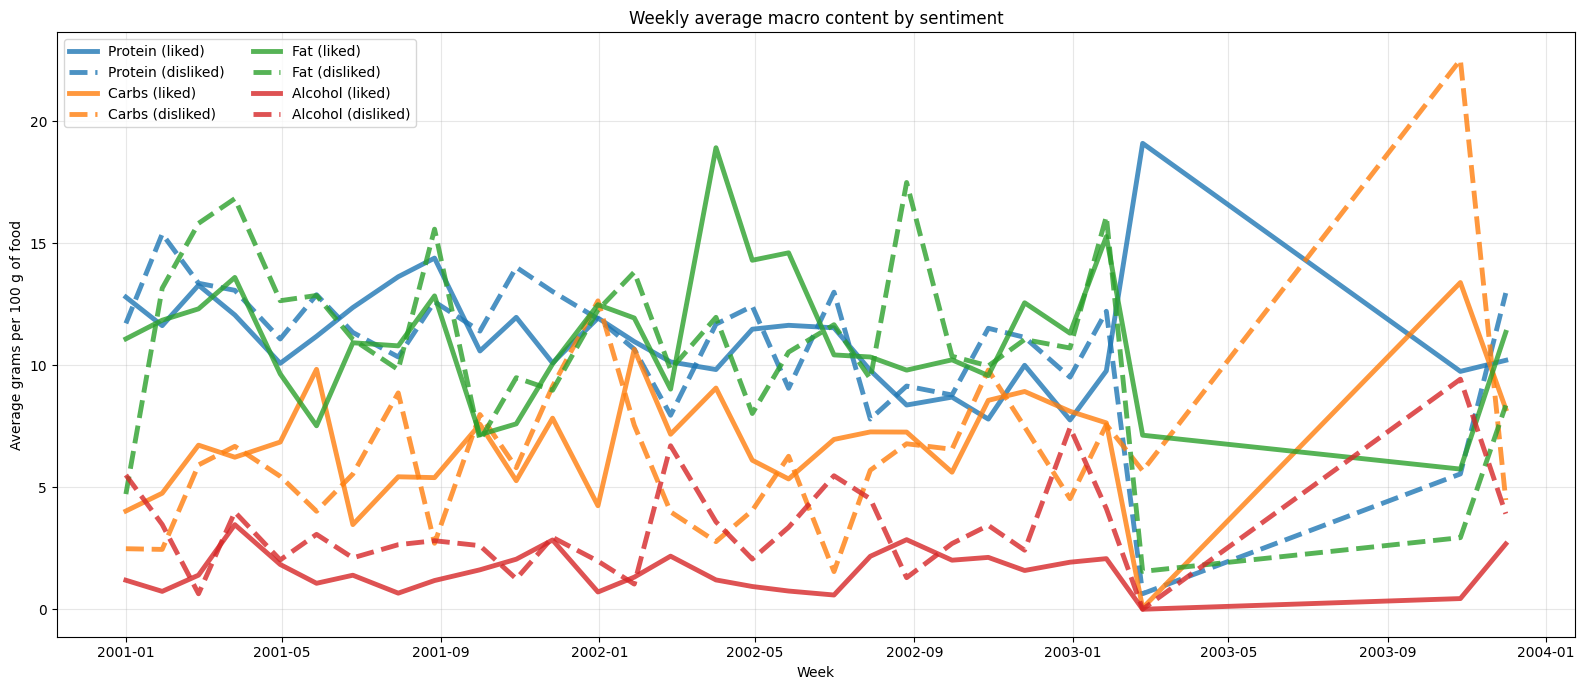

In [32]:
plt.figure(figsize=(16, 7))

colors = plt.cm.tab10.colors

for i, macro in enumerate(MACROS):
    color = colors[i]

    for sentiment, linestyle in [("liked", "-"), ("disliked", "--")]:
        data = weekly_macro[
            weekly_macro["sentiment"] == sentiment
        ].sort_values("week")

        plt.plot(
            data["week"],
            data[macro],
            label=f"{macro.replace('_g', '').capitalize()} ({sentiment})",
            color=color,
            linestyle=linestyle,
            linewidth=3.5,
            alpha=0.6
        )

plt.title("Weekly average macro content by sentiment")
plt.xlabel("Week")
plt.ylabel("Average grams per 100 g of food")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()